<a href="https://colab.research.google.com/github/Antibote/pinn-eos-aluminum/blob/main/notebooks/pinn_eos_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PINN для уравнения состояния алюминия — общий блокнот команды

Кейс 02 (ML), хакатон «ИТ КоР 5.0». Репозиторий: https://github.com/Antibote/pinn-eos-aluminum · задачи: https://github.com/Antibote/pinn-eos-aluminum/issues

**Правила работы в блокноте**
1. `Среда выполнения → Сменить среду выполнения → GPU (T4)`.
2. Каждый раз после подключения запустите раздел **0. Подготовка** — он скачает данные и код.
3. Пишите только в **своём** разделе. Среда выполнения у каждого своя: переменные коллег у вас не появятся, пока вы сами не запустите их ячейки.
 4. Все результаты (модели, normalization.json, split.npz, метрики, графики) сохраняйте в ARTIFACTS / FIGURES — это папка artifacts/ репозитория. После сохранения вызовите save_to_repo('что сохранили'): файлы уйдут на GitHub и появятся у остальных при следующем запуске раздела 0. Для этого один раз добавьте секрет Colab GITHUB_TOKEN.
5. Готовый код переносим в `src/eos/` репозитория, чтобы финальная сдача запускалась через `python run.py`.

| Раздел | Задача | Ответственный |
|---|---|---|
| 1. Данные, EDA и бейзлайн | #1 | Деревянкин Кирилл |
| 2. Vanilla-модель | #2 | Елагин Матвей |
| 3. PINN и физические ограничения | #3 | Королева Ульяна |
| 4. Инференс, упаковка и сжатие | #4 | Володченко Александра |
| 5. Сжатие и скорость работы, документация | #5 | Селивохин Ярослав |

## 0. Подготовка (общая, запускать каждому)

In [9]:
import torch
print('torch', torch.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'нет — включите GPU в настройках среды')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

torch 2.11.0+cu130
GPU: Tesla T4


In [10]:
# Репозиторий: код (src/eos) и папка artifacts — сюда сохраняются все результаты.
# На GitHub их отправляет save_to_repo('что сохранили') — см. ячейку ниже.
import json, subprocess, sys, urllib.parse, urllib.request, zipfile
from pathlib import Path

REPO = Path('pinn-eos-aluminum')
REPO_URL = 'https://github.com/Antibote/pinn-eos-aluminum.git'
_TOKEN = None


def git(*args):
    """git в папке репозитория. Токен в сообщениях об ошибке скрыт."""
    r = subprocess.run(['git', '-C', str(REPO), *args], capture_output=True, text=True)
    if r.returncode:
        msg = (r.stderr or r.stdout).strip()
        raise RuntimeError(f'git {args[0]}: ' + (msg.replace(_TOKEN, '***') if _TOKEN else msg))
    return r.stdout


if not REPO.exists():
    subprocess.run(['git', 'clone', '-q', REPO_URL, str(REPO)], check=True)
git('config', 'user.name', 'Colab')
git('config', 'user.email', 'colab@users.noreply.github.com')
git('pull', '-q', '--rebase', '--autostash')
sys.path.insert(0, str(REPO / 'src'))

ARTIFACTS = REPO / 'artifacts'
FIGURES = ARTIFACTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
print('Артефакты:', ARTIFACTS.resolve())

Артефакты: /content/pinn-eos-aluminum/artifacts


In [11]:
def save_to_repo(message):
    """Коммитит папку artifacts и отправляет её на GitHub.

    Нужен секрет Colab GITHUB_TOKEN (значок ключа слева) с правом записи в репозиторий.
    Без него функция только сообщает, где лежат файлы, — ячейки ноутбука не падают.

    Args:
        message: что сохранили, например 'Бейзлайн: метрики и карта ошибок'.
    """
    global _TOKEN
    try:
        from google.colab import userdata
        _TOKEN = userdata.get('GITHUB_TOKEN')
    except Exception:  # не Colab, секрета нет или нет доступа к нему
        _TOKEN = None
    if not _TOKEN:
        print(f'GITHUB_TOKEN не задан — результаты сохранены только в {ARTIFACTS.resolve()} (на GitHub не отправлены)')
        return

    big = [str(p) for p in ARTIFACTS.rglob('*') if p.is_file() and p.stat().st_size > 50 * 2**20]
    if big:
        raise RuntimeError(f'Файлы больше 50 МБ GitHub не примет: {big}')
    git('add', 'artifacts')
    changed = git('diff', '--cached', '--name-only', '--', 'artifacts').split()
    if not changed:
        print('Нечего сохранять: artifacts не изменилась')
        return

    # Автор коммита — владелец токена
    req = urllib.request.Request('https://api.github.com/user', headers={'Authorization': f'token {_TOKEN}'})
    me = json.load(urllib.request.urlopen(req))
    author = f"{me.get('name') or me['login']} <{me['id']}+{me['login']}@users.noreply.github.com>"

    git('commit', '-q', '-m', message, '--author', author)
    url = REPO_URL.replace('https://', f'https://x-access-token:{_TOKEN}@')
    git('pull', '-q', '--rebase', url, 'main')
    git('push', '-q', url, 'HEAD:main')
    print('На GitHub:', git('log', '-1', '--format=%h %s').strip())
    print('Файлы:', *changed, sep='\n  ')


In [14]:
# Данные с Яндекс Диска (в репозиторий не попадают)
DATA = REPO / 'data'
if not list(DATA.glob('Obl*.txt')):
    api = 'https://cloud-api.yandex.net/v1/disk/public/resources/download?' + urllib.parse.urlencode(
        {'public_key': 'https://disk.yandex.ru/d/iUSbYrJcsbXSbw', 'path': '/Материалы к хакатону.zip'})
    href = json.load(urllib.request.urlopen(api))['href']
    urllib.request.urlretrieve(href, 'data.zip')
    zipfile.ZipFile('data.zip').extractall(DATA)
print(len(list(DATA.glob('Obl*.txt'))), 'файлов данных в', DATA)

20 файлов данных в pinn-eos-aluminum/data


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from eos.data import load_all, region_grid

df = load_all(DATA)
print(df.shape)
df.head()

(1130053, 5)


,rho,T,P,e,region
0,0.001000,0.1,0.000515,-46.797895,Obl01
1,0.001030,0.1,0.000540,-46.790300,Obl01
2,0.001060,0.1,0.000569,-46.782552,Obl01
3,0.001091,0.1,0.000597,-46.774662,Obl01
4,0.001124,0.1,0.000626,-46.766630,Obl01


---
## 1. Данные, EDA и бейзлайн — Деревянкин Кирилл (#1)

- [x] EDA: распределения, проверка стыков областей
- [x] Сечения P и E при 3–4 фиксированных ρ и T
- [x] Нормировка → `ARTIFACTS / 'normalization.json'`
- [x] Разбиение train/val/test (сохранить индексы или seed)
- [x] Бейзлайн: билинейная интерполяция, точность и время на 10⁵ запросов

### 1.1 EDA

In [ ]:
import re
from pathlib import Path
import numpy as np
import pandas as pd

COLS = ["rho", "T", "P", "e"]
EXPECTED_UNITS = {"rho": "g/cm^3", "T": "K", "P": "GPa", "e": "kJ/g"}


def parse_header(path: Path) -> dict:
    """Читает строки-комментарии в начале файла."""
    h = {}
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            if not line.startswith("#"):
                break
            s = line.lstrip("#").strip()
            if m := re.match(r"Region\s+(\S+?):", s):
                h["region"] = m.group(1)
            elif m := re.match(r"rho range:\s*\[([^,]+),\s*([^\]]+)\]", s):
                h["rho_min_decl"] = float(m.group(1)); h["rho_max_decl"] = float(m.group(2))
            elif m := re.match(r"T range:\s*\[([^,]+),\s*([^\]]+)\]", s):
                h["T_min_decl"] = float(m.group(1));   h["T_max_decl"] = float(m.group(2))
            elif m := re.match(r"Grid type:\s*rho=(\w+),\s*T=(\w+)", s):
                h["grid_rho"] = m.group(1); h["grid_T"] = m.group(2)
            elif m := re.match(r"N points:\s*(\d+)", s):
                h["n_points_decl"] = int(m.group(1))
            elif m := re.match(r"Columns:\s*(.+)", s):
                h["columns"] = [c.strip() for c in m.group(1).split(",")]
            elif m := re.match(r"Units:\s*(.+)", s):
                h["units_raw"] = m.group(1)
    return h


def inventory_file(path: Path, verbose=True):
    """Читает файл, валидирует, возвращает (df, meta)."""
    h = parse_header(path)

    # проверка единиц
    units_ok = all(f"{n} [{u}]" in h.get("units_raw", "") for n, u in EXPECTED_UNITS.items())

    cols = h.get("columns", COLS)
    df = pd.read_csv(path, sep=r"\s+", header=None, comment="#",
                     names=cols, engine="python").astype(float)[COLS]

    warnings = []

    # NaN
    n_nan = int(df.isna().sum().sum())
    if n_nan:
        warnings.append(f"NaN: {n_nan}")
        df = df.dropna().reset_index(drop=True)

    # дубликаты (rho, T)
    n_dup = int(df.duplicated(subset=["rho", "T"]).sum())
    if n_dup:
        warnings.append(f"duplicates(rho,T): {n_dup}")
        df = df.drop_duplicates(subset=["rho", "T"], keep="first").reset_index(drop=True)

    # T <= 0
    n_tneg = int((df["T"] <= 0).sum())
    if n_tneg:
        warnings.append(f"T<=0: {n_tneg}")

    # rho <= 0
    n_rneg = int((df["rho"] <= 0).sum())
    if n_rneg:
        warnings.append(f"rho<=0: {n_rneg}")

    # сверка N points
    n_decl = h.get("n_points_decl")
    if n_decl is not None and n_decl != len(df):
        warnings.append(f"n_points: факт {len(df)} vs шапка {n_decl}")

    # сверка диапазонов с шапкой (допуск 10% — шапка округляет)
    for key, col, tol_rel in [("rho_min", "rho", 0.05), ("rho_max", "rho", 0.10),
                          ("T_min", "T", 0.10), ("T_max", "T", 0.10)]:
      decl_key = key + "_decl"
      if decl_key in h:
        decl = h[decl_key]
        fact = float(df[col].min() if key.endswith("min") else df[col].max())
        # сравниваем относительно ДИАПАЗОНА, а не абсолютного значения
        span = abs(h.get("rho_max_decl", 1) - h.get("rho_min_decl", 0)) if col == "rho" \
               else abs(h.get("T_max_decl", 1) - h.get("T_min_decl", 0))
        if span > 0 and abs(fact - decl) > tol_rel * span:
            warnings.append(f"{key}: факт {fact:.6g} vs шапка {decl:.6g}")

    if not units_ok:
        warnings.append(f"units: {h.get('units_raw')}")

    # тип сетки — берём из шапки
    grid_rho = h.get("grid_rho", "?")
    grid_T   = h.get("grid_T", "?")

    meta = {
        "region": h.get("region", path.stem),
        "file": path.name,
        "n_points": len(df),
        "n_points_decl": n_decl,
        "rho_min": float(df["rho"].min()), "rho_max": float(df["rho"].max()),
        "T_min": float(df["T"].min()),     "T_max": float(df["T"].max()),
        "P_min": float(df["P"].min()),     "P_max": float(df["P"].max()),
        "e_min": float(df["e"].min()),     "e_max": float(df["e"].max()),
        "grid_rho": grid_rho,
        "grid_T": grid_T,
        "grid": f"{grid_rho} x {grid_T}",
        "units_ok": units_ok,
        "warnings": "; ".join(warnings) if warnings else "",
    }
    if verbose and warnings:
        print(f"{path.name}: " + "; ".join(warnings))
    return df, meta


def inventory_all(data_dir: Path):
    files = sorted(Path(data_dir).glob("Obl*.txt"))
    rows = []
    for p in files:
        _, m = inventory_file(p)
        rows.append(m)
    return pd.DataFrame(rows)


# --- запуск ---
DATA_DIR = DATA
meta_df = inventory_all(DATA_DIR)

cols_show = ["region", "n_points", "n_points_decl", "grid_rho", "grid_T",
             "rho_min", "rho_max", "T_min", "T_max",
             "P_min", "P_max", "e_min", "e_max", "warnings"]
meta_df = meta_df[cols_show]

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
print(meta_df.to_string(index=False))

region  n_points  n_points_decl grid_rho grid_T  rho_min      rho_max    T_min        T_max       P_min        P_max      e_min         e_max warnings
 Obl01     24964          24964      log    log    0.001     0.097127      0.1 9.572220e+01    0.000515 1.535523e+00 -46.797895    -38.925270         
 Obl02     40000          40000      log    log    0.001     0.097724    100.0 2.949413e+03    0.496257 1.588391e+01 -46.659548    -34.464034         
 Obl03     40000          40000      log    log    0.001     0.097724   3000.0 2.965659e+04   14.957272 1.537386e+02 -37.526602     87.144065         
 Obl04     75076          75076      log    lin    0.001     0.098333  30000.0 9.974453e+04  149.730913 5.216896e+02  62.301693    448.562065         
 Obl05     40000          40000      log    log    0.001     0.097724 100000.0 1.000000e+07  499.136847 6.018982e+04 404.610858 167860.034500         
 Obl06     24964          24964      log    log    0.100     1.474510      0.1 9.572220e+01   

In [ ]:
meta_df["grid"] = meta_df["grid_rho"] + " x " + meta_df["grid_T"]
print(meta_df["grid"].value_counts().to_string())

print("\nВсего областей:", len(meta_df))
print("Всего точек:  ", f"{meta_df['n_points'].sum():,}")

n = meta_df["n_points"]
med = n.median()
outliers = meta_df[(n > 3 * med) | (n < med / 3)]
print("=== Области-выбросы по числу точек (>3× медианы или <1/3) ===")
if len(outliers):
    print(outliers[["region", "n_points", "grid"]].to_string(index=False))
else:
    print("Нет: все области в пределах [median/3, 3×median]")

# топ-3 самых крупных и самых мелких
print("\nТоп-3 крупнейших:")
print(meta_df.nlargest(3, "n_points")[["region", "n_points"]].to_string(index=False))
print("\nТоп-3 мельчайших:")
print(meta_df.nsmallest(3, "n_points")[["region", "n_points"]].to_string(index=False))

grid
log x log    12
lin x log     4
log x lin     3
lin x lin     1

Всего областей: 20
Всего точек:   1,130,053
=== Области-выбросы по числу точек (>3× медианы или <1/3) ===
Нет: все области в пределах [median/3, 3×median]

Топ-3 крупнейших:
region  n_points
 Obl14     99856
 Obl12     90000
 Obl13     90000

Топ-3 мельчайших:
region  n_points
 Obl01     24964
 Obl06     24964
 Obl16     24964


In [ ]:
# Глобальные диапазоны (по всем 20 областям). Колонки df: rho, T, P, e, region

def n_orders(lo, hi):
    """Сколько порядков между lo и hi; для знакопеременного диапазона — NaN."""
    if lo <= 0 or hi <= 0:
        return np.nan
    return np.log10(hi / lo)

rows = []
for col in ["rho", "T", "P", "e"]:
    x = df[col].values
    lo, hi = float(np.min(x)), float(np.max(x))
    rows.append({
        "величина": col,
        "min": lo,
        "max": hi,
        "mean": float(np.mean(x)),
        "std": float(np.std(x)),
        "median": float(np.median(x)),
        "порядков (max/min)": n_orders(lo, hi),
        "знакопеременная": bool(lo < 0 < hi),
        "есть отрицательные": bool(lo < 0),
    })

ranges = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
print("=== Глобальные диапазоны (по всем 20 областям) ===")
print(ranges.to_string(index=False))

=== Глобальные диапазоны (по всем 20 областям) ===
величина       min       max      mean       std    median  порядков (max/min)  знакопеременная  есть отрицательные
     rho     0.001     1e+04     307.6      1210     2.257                   7            False               False
       T       0.1     1e+07 4.043e+05 1.338e+06 2.075e+04                   8            False               False
       P 0.0005154 1.591e+09  8.31e+06 5.958e+07       465               12.49            False               False
       e     -46.8 1.679e+05      5833 1.975e+04     115.9                 NaN             True                True


- ≤ 1–2 порядка → можно подавать как есть (z-score или min-max).
- 3–8 порядков → нужен log, иначе сеть не различит малые значения.
- больше 10 порядков (давление) → log, затем z-score.
- Знакопеременная величина (энергия e) → обычный log невозможен, но и чистый z-score не подходит: он не меняет форму распределения (skew и kurtosis у `e` и `z(e)` одинаковые), и 77% точек оказываются в нижнем 1% шкалы. Нужен «логарифм со знаком» `asinh(e)` или сдвинутый логарифм `log10(e − e_min + 1)`, затем z-score.
Текстовую ячейку «log(e) — нельзя;» после неё можно удалить: правило теперь описано здесь.

In [ ]:
e = df["e"].values
n_neg = int((e < 0).sum())
n_zero = int((e == 0).sum())
n_pos = int((e > 0).sum())
total = len(e)

print("=== Знак e ===")
print(f"отрицательных: {n_neg:>8,}  ({100*n_neg/total:5.1f}%)")
print(f"нулевых:       {n_zero:>8,}  ({100*n_zero/total:5.1f}%)")
print(f"положительных: {n_pos:>8,}  ({100*n_pos/total:5.1f}%)")
print(f"всего:         {total:>8,}")

# где именно отрицательные — по областям
neg_by_region = df.assign(is_neg=df["e"] < 0).groupby("region")["is_neg"].mean()
print("\nДоля отрицательных e по областям, %:")
print((neg_by_region * 100).round(1).to_string())

=== Знак e ===
отрицательных:  219,302  ( 19.4%)
нулевых:              0  (  0.0%)
положительных:  910,751  ( 80.6%)
всего:         1,130,053

Доля отрицательных e по областям, %:
region
Obl01    100
Obl02    100
Obl03   60.8
Obl04      0
Obl05      0
Obl06    100
Obl07   99.8
Obl08   57.3
Obl09      0
Obl10      0
Obl11   11.1
Obl12    5.8
Obl13      0
Obl14      0
Obl15      0
Obl16      0
Obl17      0
Obl18      0
Obl19      0
Obl20      0


log(e) — нельзя;

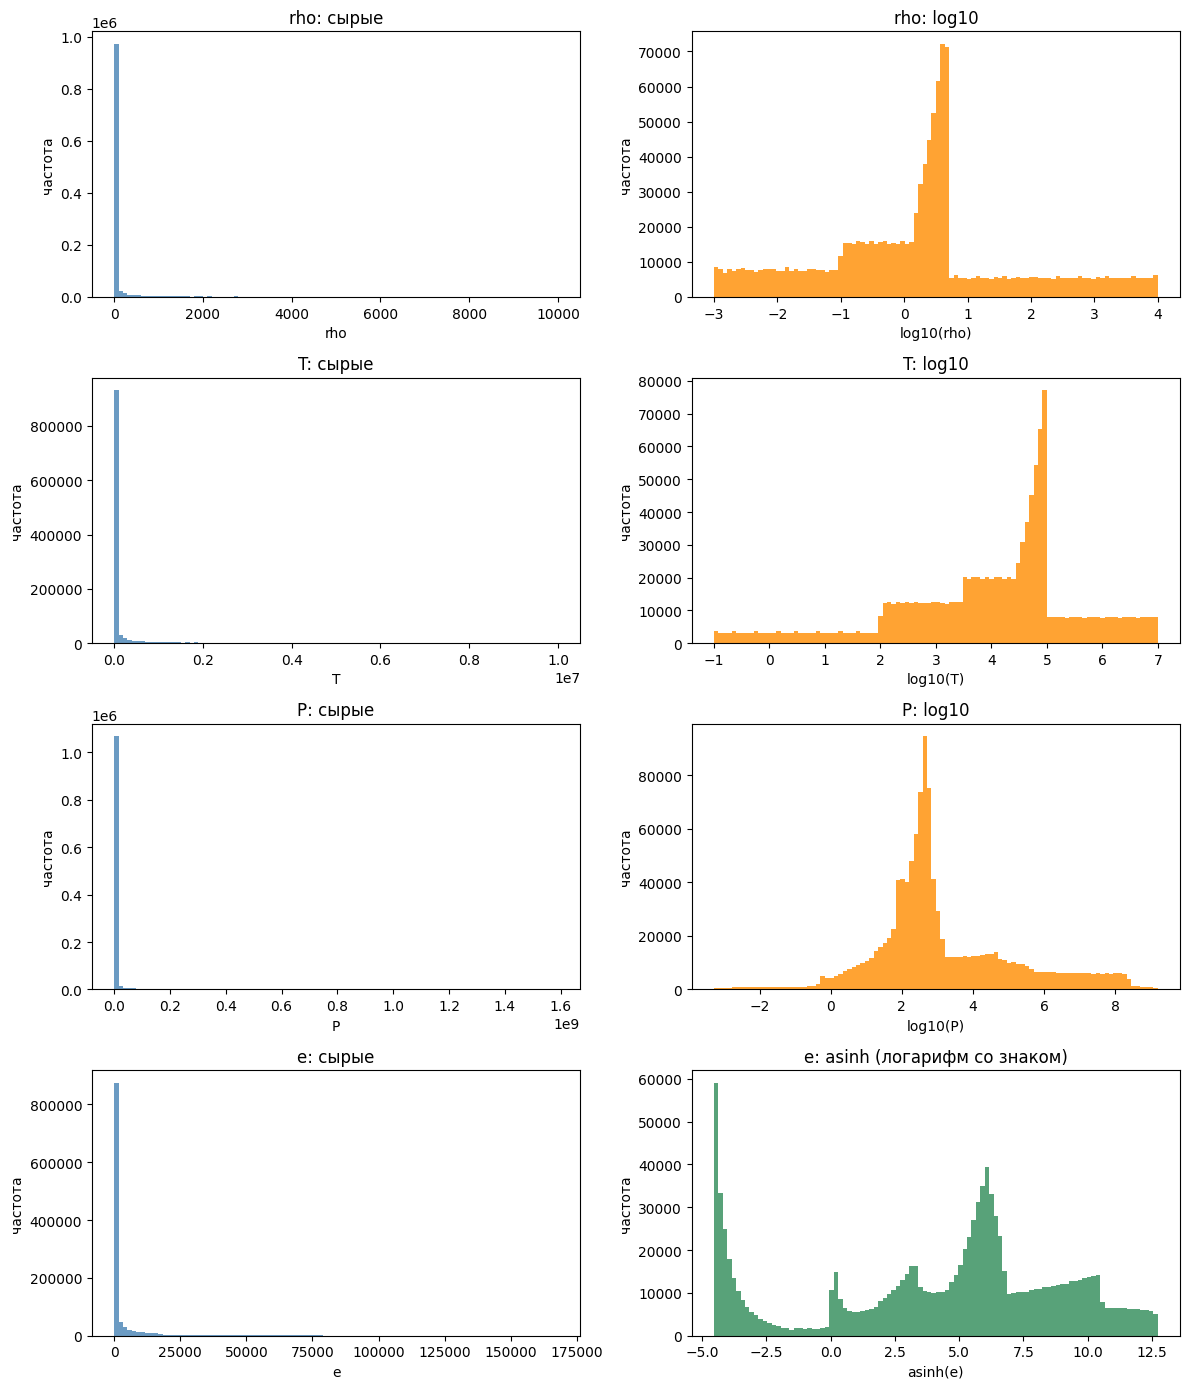

Сохранено: pinn-eos-aluminum/artifacts/figures/eda_scales/hist_raw_vs_log.png


In [ ]:
import matplotlib.pyplot as plt

FIG = FIGURES / "eda_scales"
FIG.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(4, 2, figsize=(12, 14))

for i, col in enumerate(["rho", "T", "P", "e"]):
    x = df[col].values

    # левая колонка — сырые значения
    ax = axes[i, 0]
    ax.hist(x, bins=100, color="steelblue", alpha=0.8)
    ax.set_title(f"{col}: сырые")
    ax.set_xlabel(col)
    ax.set_ylabel("частота")

    # правая колонка — log10 для положительных, asinh для знакопеременной e
    ax = axes[i, 1]
    if np.all(x > 0):
        ax.hist(np.log10(x), bins=100, color="darkorange", alpha=0.8)
        ax.set_title(f"{col}: log10")
        ax.set_xlabel(f"log10({col})")
    else:
        ax.hist(np.arcsinh(x), bins=100, color="seagreen", alpha=0.8)
        ax.set_title(f"{col}: asinh (логарифм со знаком)")
        ax.set_xlabel(f"asinh({col})")
    ax.set_ylabel("частота")

plt.tight_layout()
out = FIG / "hist_raw_vs_log.png"
plt.savefig(out, dpi=120, bbox_inches="tight")
plt.show()
print("Сохранено:", out)

In [ ]:
from scipy import stats

def describe(x, name):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    lo, hi = x.min(), x.max()
    return {
        "величина": name,
        "n": len(x),
        "skew": float(stats.skew(x)),
        "kurtosis": float(stats.kurtosis(x)),
        "std": float(np.std(x)),
        "в нижнем 1% шкалы, %": 100 * float((x < lo + 0.01 * (hi - lo)).mean()),
    }

rows = []
for col in ["rho", "T", "P"]:
    x = df[col].values
    rows.append(describe(x, f"{col} (сырое)"))
    rows.append(describe(np.log10(x), f"log10({col})"))
e = df["e"].values
rows.append(describe(e, "e (сырое)"))
rows.append(describe((e - e.mean()) / e.std(), "e (z-score)"))
rows.append(describe(np.arcsinh(e), "asinh(e)"))
rows.append(describe(np.log10(e - e.min() + 1), "log10(e - e_min + 1)"))

norm_check = pd.DataFrame(rows)
print("=== Асимметрия и эксцесс (0 = нормальное распределение) ===")
print(norm_check.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

=== Асимметрия и эксцесс (0 = нормальное распределение) ===
            величина       n   skew  kurtosis          std  в нижнем 1% шкалы, %
         rho (сырое) 1130053  5.185    28.917     1209.581                86.074
          log10(rho) 1130053  0.229    -0.021        1.560                 0.751
           T (сырое) 1130053  4.555    22.015  1338240.098                82.376
            log10(T) 1130053 -0.799     0.539        1.665                 0.328
           P (сырое) 1130053 14.145   251.203 59576612.912                94.344
            log10(P) 1130053  0.675     0.811        1.969                 0.055
           e (сырое) 1130053  4.994    27.328    19746.675                77.392
         e (z-score) 1130053  4.994    27.328        1.000                77.392
            asinh(e) 1130053 -0.473    -0.743        4.793                 5.226
log10(e - e_min + 1) 1130053  0.595    -0.113        1.081                 0.197


skew (асимметрия): 0 — симметрично; >1 или <−1 — сильно скошено.

kurtosis (эксцесс): 0 — как у нормального; >3 — тяжёлые хвосты.

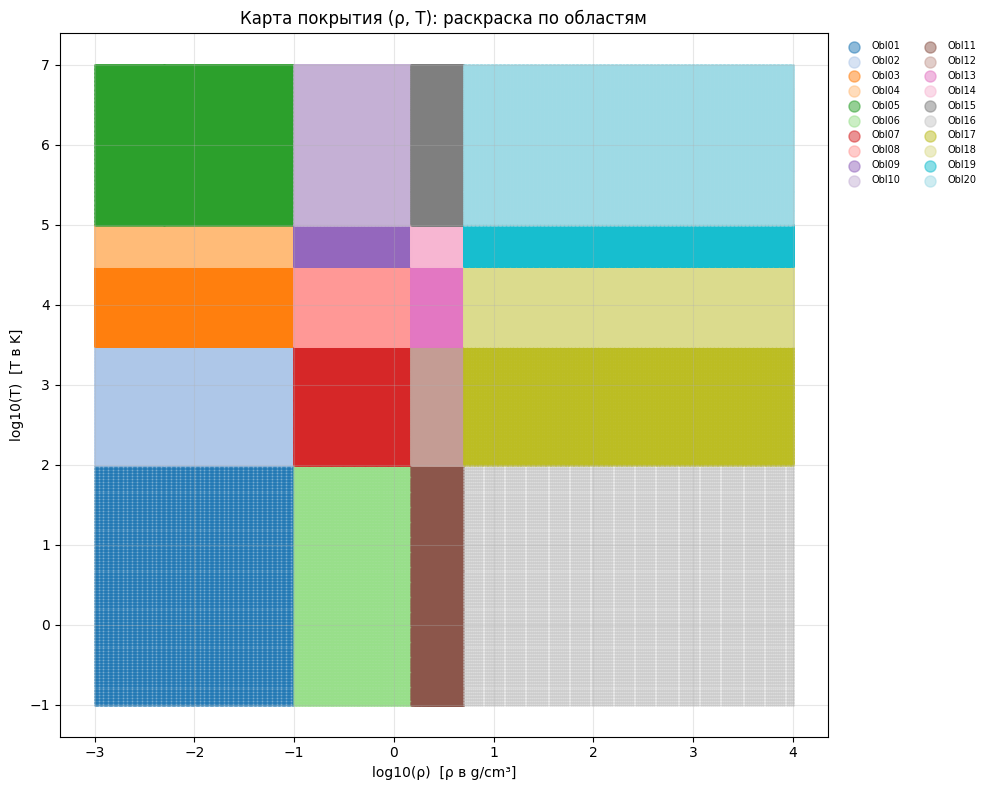

Сохранено: pinn-eos-aluminum/artifacts/figures/eda_coverage/coverage_by_region.png


In [ ]:
# Работаем с копией, чтобы не добавлять колонки в общую df
cov = df.assign(
    log_rho=np.log10(df["rho"].values),
    log_T=np.log10(df["T"].values),
)

FIG = FIGURES / "eda_coverage"
FIG.mkdir(parents=True, exist_ok=True)

regions = sorted(cov["region"].unique())
cmap = plt.get_cmap("tab20")
colors = {r: cmap(i % 20) for i, r in enumerate(regions)}

fig, ax = plt.subplots(figsize=(10, 8))
for r in regions:
    sub = cov[cov["region"] == r]
    ax.scatter(sub["log_rho"], sub["log_T"],
               s=1, alpha=0.5, color=colors[r], label=r, rasterized=True)

ax.set_xlabel("log10(ρ)  [ρ в g/cm³]")
ax.set_ylabel("log10(T)  [T в K]")
ax.set_title("Карта покрытия (ρ, T): раскраска по областям")
ax.grid(True, alpha=0.3)
ax.legend(markerscale=8, fontsize=7, ncol=2, loc="upper left",
          bbox_to_anchor=(1.01, 1.0), frameon=False)

plt.tight_layout()
out = FIG / "coverage_by_region.png"
plt.savefig(out, dpi=130, bbox_inches="tight")
plt.show()
print("Сохранено:", out)


In [ ]:
# Неравномерная плотность точек: линейные сетки в двух полосах дают пики
bands = [
    ("rho", 1.5, 5.0, 1e-3, 1e4, "ρ от 1,5 до 5 г/см³ (лин. сетка)"),
    ("T", 3e4, 1e5, 0.1, 1e7, "T от 3·10⁴ до 10⁵ K (лин. сетка)"),
]
print("=== Доля точек против доли диапазона (в лог-шкале) ===")
for col, lo, hi, full_lo, full_hi, name in bands:
    share_range = (np.log10(hi) - np.log10(lo)) / (np.log10(full_hi) - np.log10(full_lo))
    share_points = ((df[col] >= lo) & (df[col] < hi)).mean()
    print(f"{name}: {100*share_range:.1f}% диапазона, {100*share_points:.1f}% точек")
print("\nВывод: при обучении на всех точках эти полосы будут доминировать в loss —"
      "\nнужны веса или выборка батчей равномерно по областям (передать в #2).")

=== Доля точек против доли диапазона (в лог-шкале) ===
ρ от 1,5 до 5 г/см³ (лин. сетка): 7.5% диапазона, 34.5% точек
T от 3·10⁴ до 10⁵ K (лин. сетка): 6.5% диапазона, 28.8% точек

Вывод: при обучении на всех точках эти полосы будут доминировать в loss —
нужны веса или выборка батчей равномерно по областям (передать в #2).


In [ ]:
# Особенности данных, важные для PINN: где сами таблицы нарушают ∂e/∂T ≥ 0 и ∂P/∂T ≥ 0
rows = []
for name, g in df.groupby("region"):
    rho, T, P, e = region_grid(g)
    de, dP = np.diff(e, axis=0), np.diff(P, axis=0)
    rows.append({
        "region": name,
        "de/dT = 0 (плато), %": 100 * (de == 0).mean(),
        "de/dT < 0, шт": int((de < 0).sum()),
        "dP/dT < 0, шт": int((dP < 0).sum()),
        "dP/dρ ≤ 0, шт": int((np.diff(P, axis=1) <= 0).sum()),
    })
anom = pd.DataFrame(rows)
print(anom[(anom.iloc[:, 1:] > 0).any(axis=1)].to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# Шов при T ≈ 142 K: при нагреве P падает на ~30% при любой плотности
rho, T, P, e = region_grid(df[df["region"] == "Obl02"])
i = np.searchsorted(T, 142.0)
print("\nObl02, ρ = 0.001 г/см³ — шов в таблице:")
for k in range(i - 2, i + 2):
    print(f"  T = {T[k]:7.2f} K   P = {P[k, 0]:.4f} ГПа   e = {e[k, 0]:.4f} кДж/г")

region  de/dT = 0 (плато), %  de/dT < 0, шт  dP/dT < 0, шт  dP/dρ ≤ 0, шт
 Obl01                   1.0              0            144              0
 Obl02                   0.0            200            200              0
 Obl04                   0.0             20              0              0
 Obl06                   8.9              0            143              0
 Obl07                   0.0            245            245              0
 Obl11                   6.0              0            393              0
 Obl12                   0.0            300            300              0
 Obl16                  44.1              0            235              0
 Obl17                   0.0            200            200              0

Obl02, ρ = 0.001 г/см³ — шов в таблице:
  T =  138.14 K   P = 0.6897 ГПа   e = -46.5866 кДж/г
  T =  140.51 K   P = 0.7015 ГПа   e = -46.5817 кДж/г
  T =  142.92 K   P = 0.4963 ГПа   e = -46.6170 кДж/г
  T =  145.37 K   P = 0.5088 ГПа   e = -46.6119 кДж/г


### 1.2 Сечения

Загружено областей: 20
Фиксированные плотности: [1.30000000e-03 2.35133469e-01 4.25290370e+01 7.69230769e+03]
Фиксированные температуры: [1.30000000e-01 5.06579702e+01 1.97402303e+04 7.69230769e+06]


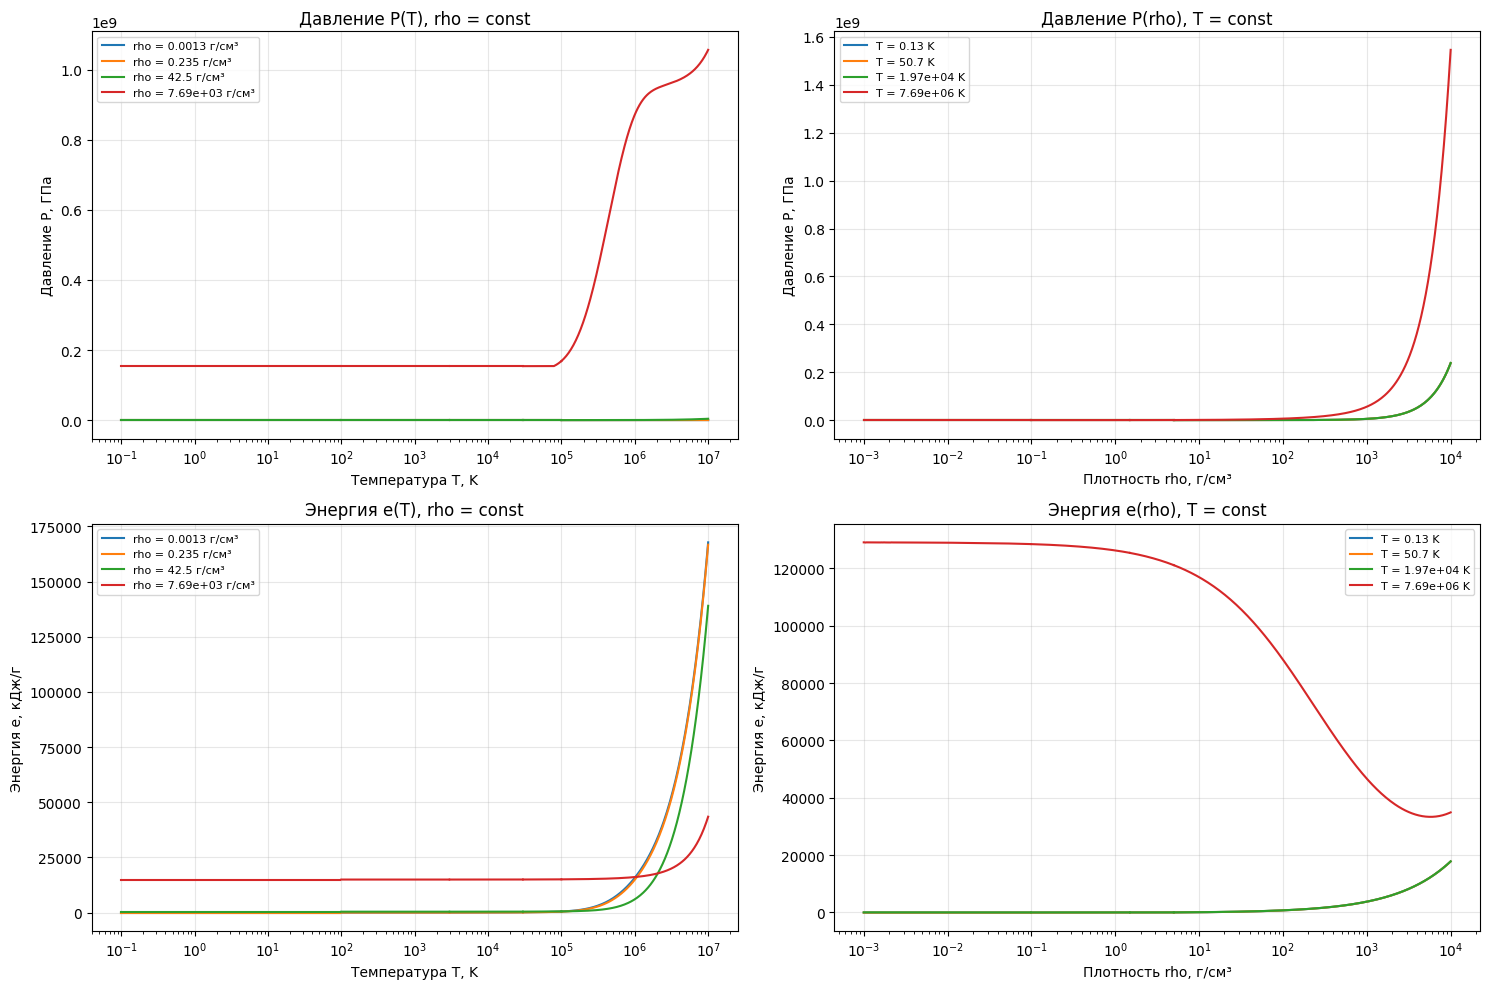

График сохранён: pinn-eos-aluminum/artifacts/figures/eos_sections.png


In [ ]:

# Тип сетки каждой области из твоего EDA
grid_meta = (
    meta_df.set_index("region")[["grid_rho", "grid_T"]]
    .to_dict("index")
)

# Преобразуем таблицы в двумерные сетки
# P и e имеют размерность (количество T, количество rho)
grids = {
    str(region): region_grid(g)
    for region, g in df.groupby("region")
}

print("Загружено областей:", len(grids))


# Функция преобразования координат

def transform(x, kind):
    if kind == "log":
        return np.log10(x)
    return x


# Получаем сечение одной области

def get_section(region, fixed_value, fixed_parameter,
                coordinate_mode="grid"):
    """
    Возвращает сечение P и e при фиксированной rho или T.

    Args:
        region: название области, например "Obl02".
        fixed_value: фиксированная плотность или температура.
        fixed_parameter: "rho" или "T".
        coordinate_mode: "grid" или "physical".

    Returns:
        (x, P_section, e_section) или None.
    """

    rho, T, P, e = grids[region]

    if fixed_parameter == "rho":
        axis = rho
        kind = grid_meta[region]["grid_rho"]

    elif fixed_parameter == "T":
        axis = T
        kind = grid_meta[region]["grid_T"]

    else:
        raise ValueError("fixed_parameter должен быть 'rho' или 'T'")

    # Если точка вне данной области, пропускаем её
    if fixed_value < axis[0] or fixed_value > axis[-1]:
        return None

    if len(axis) < 2:
        return None

    # Интерполяция в физических или сеточных координатах
    if coordinate_mode == "physical":
        kind = "lin"
    elif coordinate_mode != "grid":
        raise ValueError("Некорректный coordinate_mode")

    axis_new = transform(axis, kind)
    value_new = transform(fixed_value, kind)

    # Находим соседние узлы
    i = np.searchsorted(axis_new, value_new, side="right") - 1
    i = int(np.clip(i, 0, len(axis_new) - 2))

    # Коэффициент линейной интерполяции
    w = (
        (value_new - axis_new[i])
        / (axis_new[i + 1] - axis_new[i])
    )

    if fixed_parameter == "rho":
        # Фиксируем плотность, изменяем T
        P_section = (1-w)*P[:, i] + w*P[:, i+1]
        e_section = (1-w)*e[:, i] + w*e[:, i+1]

        return T, P_section, e_section

    else:
        # Фиксируем температуру, изменяем rho
        P_section = (1-w)*P[i, :] + w*P[i+1, :]
        e_section = (1-w)*e[i, :] + w*e[i+1, :]

        return rho, P_section, e_section


# Выбираем значения для сечений

# значения плотности по всему диапазону
rho_levels = np.geomspace(
    df["rho"].min() * 1.3,
    df["rho"].max() / 1.3,
    4
)

# значения температуры по всему диапазону
T_levels = np.geomspace(
    df["T"].min() * 1.3,
    df["T"].max() / 1.3,
    4
)

print("Фиксированные плотности:", rho_levels)
print("Фиксированные температуры:", T_levels)

# Варианты:
# "grid" — в координатах типа сетки
# "physical" — в обычных rho и T
COORD_MODE = "grid"


fig, axes = plt.subplots(2, 2, figsize=(15, 10))

colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

# Сечения при фиксированной плотности
for j, rho0 in enumerate(rho_levels):

    first = True

    for region in grids:
        result = get_section(
            region, rho0, "rho", COORD_MODE
        )

        if result is None:
            continue

        T, P, e = result
        label = f"rho = {rho0:.3g} г/см³" if first else None

        axes[0, 0].plot(
            T, P, color=colors[j],
            linewidth=1.5, label=label
        )

        axes[1, 0].plot(
            T, e, color=colors[j],
            linewidth=1.5, label=label
        )

        first = False

    if first:
        print(f"Нет областей для rho={rho0:.5g}")


# Сечения при фиксированной температуре
for j, T0 in enumerate(T_levels):

    first = True

    for region in grids:
        result = get_section(
            region, T0, "T", COORD_MODE
        )

        if result is None:
            continue

        rho, P, e = result
        label = f"T = {T0:.3g} K" if first else None

        axes[0, 1].plot(
            rho, P, color=colors[j],
            linewidth=1.5, label=label
        )

        axes[1, 1].plot(
            rho, e, color=colors[j],
            linewidth=1.5, label=label
        )

        first = False

    if first:
        print(f"Нет областей для T={T0:.5g}")


# Оформление

axes[0, 0].set_title("Давление P(T), rho = const")
axes[1, 0].set_title("Энергия e(T), rho = const")

axes[0, 1].set_title("Давление P(rho), T = const")
axes[1, 1].set_title("Энергия e(rho), T = const")

for ax in axes[:, 0]:
    ax.set_xlabel("Температура T, K")
    ax.set_xscale("log")

for ax in axes[:, 1]:
    ax.set_xlabel("Плотность rho, г/см³")
    ax.set_xscale("log")

for ax in axes[0, :]:
    ax.set_ylabel("Давление P, ГПа")

for ax in axes[1, :]:
    ax.set_ylabel("Энергия e, кДж/г")

for ax in axes.flat:
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()

# Сохранение результата
out = FIGURES / "eos_sections.png"
plt.savefig(out, dpi=160, bbox_inches="tight")
plt.show()

print("График сохранён:", out)


### 1.3 Нормировка и разбиение

In [ ]:
import importlib, json
import eos.model as em, eos.normalize as nz
importlib.reload(nz); importlib.reload(em)

# Разбиение: train — узлы прореженной сетки (как в бейзлайне 1.4),
# остальные узлы случайно делятся на val (20%) и test (80%)
split = em.make_split(df, val_frac=0.2, seed=0)
np.savez_compressed(ARTIFACTS / 'split.npz', **split)
print('Размеры:', {k: len(v) for k, v in split.items()})

# Веса точек для loss: выравнивают плотность сетки (линейные полосы иначе доминируют)
train_df = df.iloc[split['train']]
w_train = em.region_weights(train_df)
print(f'Веса train: min {w_train.min():.3f}, max {w_train.max():.3f}')

# Нормировка (sklearn.preprocessing), параметры только по train:
# log10 ρ, log10 T → MinMaxScaler [-1, 1]; log10 P и asinh(e/E0) → RobustScaler
norm = nz.EOSNormalizer(E0=1.0).fit(train_df['rho'], train_df['T'], train_df['P'], train_df['e'])
norm.save(ARTIFACTS / 'normalization.json')
print(open(ARTIFACTS / 'normalization.json').read())

save_to_repo('1.3: разбиение и нормировка (sklearn)')

Размеры: {'train': 286521, 'val': 168706, 'test': 674826}
Веса train: min 0.055, max 7.918
{
  "x_cols": [
    "log10_rho",
    "log10_T"
  ],
  "x_min": [
    -3.0,
    -1.0
  ],
  "x_max": [
    4.0,
    7.0
  ],
  "x_range": [
    -1.0,
    1.0
  ],
  "y_cols": [
    "log10_P",
    "asinh_e_over_E0"
  ],
  "y_center": [
    2.6690285282220985,
    5.443480963872525
  ],
  "y_scale": [
    2.0066819484820697,
    6.287397627309818
  ],
  "E0": 1.0,
  "units": {
    "rho": "g/cm^3",
    "T": "K",
    "P": "GPa",
    "e": "kJ/g"
  }
}
Нечего сохранять: artifacts не изменилась


### 1.4 Бейзлайн

model             Baseline (билинейная)
n_test                           674826
err_P_median_%                0.0004526
err_P_mean_%                   0.008127
err_P_p99_%                     0.04427
err_P_max_%                       20.39
err_e_median_%                  0.00396
err_e_mean_%                    0.01911
err_e_p99_%                      0.1683
err_e_max_%                       13.62
viol_dP_drho_%                  0.04727
viol_de_dT_%                     0.4572
viol_dP_dT_%                     0.7414
time_1e5_s                      0.06667
size_MB                           34.49


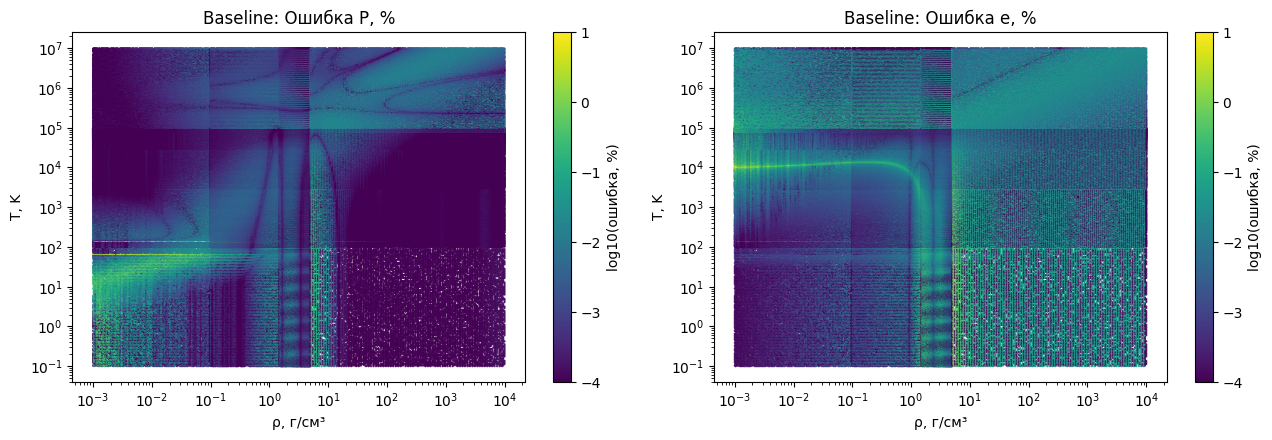

region      rho     T      P  P_pred  err_P
 Obl02 0.001047 142.9 0.4963  0.5975 0.2039
 Obl02 0.001072 142.9 0.4963  0.5975 0.2039
 Obl02 0.001096 142.9 0.4963  0.5975 0.2039
 Obl02 0.001175 142.9 0.4964  0.5976 0.2038
 Obl02 0.001202 142.9 0.4964  0.5976 0.2038
На GitHub: 5ba4047 1.4: бейзлайн — метрики и карта ошибок
Файлы:
  artifacts/metrics_baseline.json


In [ ]:
import importlib, json
import eos.baseline as bl, eos.metrics as mt
importlib.reload(bl); importlib.reload(mt)

split = dict(np.load(ARTIFACTS / 'split.npz'))  # из 1.3: тот же test будет у Vanilla и PINN
test_df = df.iloc[split['test']]

# Точность: интерполятор строится только по train-узлам (прореженная сетка)
baseline_train = bl.BilinearEOS(df, decimate=True)
metrics, per_point = mt.evaluate(baseline_train.predict, test_df, name='Baseline (билинейная)')

# Скорость и размер: рабочая версия по всей таблице, 10^5 случайных запросов
baseline = bl.BilinearEOS(df)
sec = bl.benchmark(baseline, n=100_000)
metrics['time_1e5_s'] = sec
metrics['size_MB'] = df[['rho', 'T', 'P', 'e']].to_numpy().nbytes / 2**20  # таблица в памяти

with open(ARTIFACTS / 'metrics_baseline.json', 'w') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
print(pd.Series(metrics).to_string())

# Карта ошибок на плоскости (ρ, T)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col, title in [(ax[0], 'err_P', 'Ошибка P, %'), (ax[1], 'err_e', 'Ошибка e, %')]:
    sc = a.scatter(per_point['rho'], per_point['T'], c=np.log10(per_point[col] * 100 + 1e-6),
                   s=0.3, cmap='viridis', vmin=-4, vmax=1, rasterized=True)
    a.set(xscale='log', yscale='log', xlabel='ρ, г/см³', ylabel='T, K', title=f'Baseline: {title}')
    plt.colorbar(sc, ax=a, label='log10(ошибка, %)')
plt.tight_layout()
plt.savefig(FIGURES / 'baseline_errors.png', dpi=150)
plt.show()

# Где ошибка максимальна (ожидаемо — шов в таблице при T ≈ 142 K)
print(per_point.nlargest(5, 'err_P')[['region', 'rho', 'T', 'P', 'P_pred', 'err_P']].to_string(index=False))

save_to_repo('1.4: бейзлайн — метрики и карта ошибок')

---
## 2. Vanilla-модель — Елагин Матвей (#2)

- [x] MLP на PyTorch (ρ, T → P, E) на `DEVICE`
- [x] Кривые обучения
- [x] Производные через autograd
- [x] Тепловая карта ошибок и карта нарушений
- [x] Сохранить веса в `ARTIFACTS / 'vanilla.pt'`

In [ ]:
import json
import time
import importlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

import eos.metrics as mt
import eos.model as em
import eos.normalize as nz

importlib.reload(mt); importlib.reload(em); importlib.reload(nz)

split = dict(np.load(ARTIFACTS / "split.npz"))
norm  = nz.EOSNormalizer.load(ARTIFACTS / "normalization.json")

test_df = df.iloc[split["test"]]
idx_train, idx_val, idx_test = split["train"], split["val"], split["test"]

print("split:", {k: len(v) for k, v in split.items()})
print("test областей:", test_df["region"].nunique())

split: {'train': 286521, 'val': 168706, 'test': 674826}
test областей: 20


### 2.1 Модель и обучение

MLP 2 → 256×4 → 2 (SiLU) на DEVICE.

Данные нормированы через norm.transform_x / norm.transform_y (та же нормировка, что у PINN).

Веса точек em.region_weights — чтобы полосы ρ ∈ [1.5, 5] и T ∈ [3·10⁴, 10⁵] не доминировали.

Обучение: AdamW, ReduceLROnPlateau, early stopping по val.

Параметров: 198,658
ep   0  train 0.46192  val 0.13455  lr 1.00e-03
ep  10  train 0.00402  val 0.00499  lr 1.00e-03
ep  20  train 0.00181  val 0.00248  lr 1.00e-03
ep  30  train 0.00123  val 0.00213  lr 1.00e-03
ep  40  train 0.00103  val 0.00176  lr 1.00e-03
ep  50  train 0.00092  val 0.00168  lr 1.00e-03
ep  60  train 0.00060  val 0.00115  lr 1.00e-03
ep  70  train 0.00052  val 0.00108  lr 1.00e-03
ep  80  train 0.00037  val 0.00059  lr 1.00e-03
ep  90  train 0.00026  val 0.00043  lr 1.00e-03
ep 100  train 0.00023  val 0.00049  lr 1.00e-03
ep 110  train 0.00013  val 0.00025  lr 5.00e-04
ep 120  train 0.00011  val 0.00021  lr 5.00e-04
ep 130  train 0.00010  val 0.00018  lr 5.00e-04
ep 140  train 0.00010  val 0.00018  lr 5.00e-04
ep 150  train 0.00009  val 0.00014  lr 5.00e-04
ep 160  train 0.00009  val 0.00013  lr 5.00e-04
ep 170  train 0.00006  val 0.00011  lr 2.50e-04
ep 180  train 0.00005  val 0.00010  lr 2.50e-04
ep 190  train 0.00005  val 0.00010  lr 2.50e-04
ep 200  train 0.0000

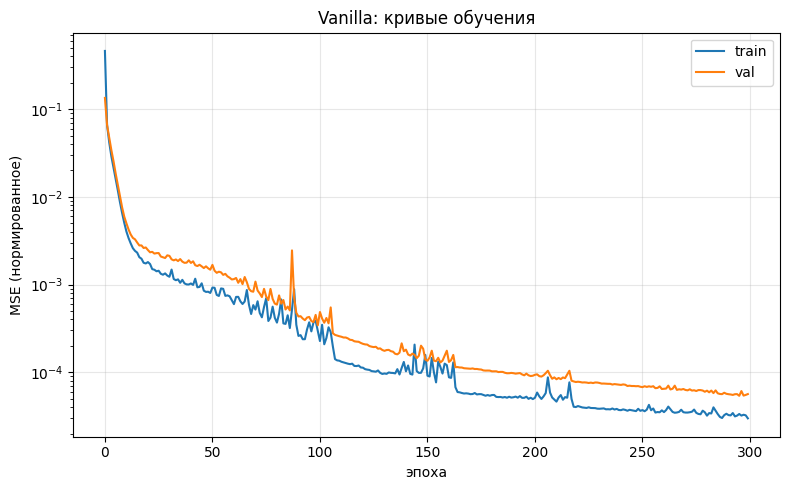

In [ ]:
def make_xy(idx):
    sub = df.iloc[idx]
    X = norm.transform_x(sub["rho"].values, sub["T"].values).astype(np.float32)
    Y = norm.transform_y(sub["P"].values, sub["e"].values).astype(np.float32)
    return X, Y

X_train, Y_train = make_xy(idx_train)
X_val,   Y_val   = make_xy(idx_val)
X_test,  Y_test  = make_xy(idx_test)

class MLP(nn.Module):
    def __init__(self, hidden=256, depth=4, activation=nn.SiLU):
        super().__init__()
        layers, in_dim = [], 2
        for _ in range(depth):
            layers += [nn.Linear(in_dim, hidden), activation()]
            in_dim = hidden
        layers += [nn.Linear(in_dim, 2)]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

model = MLP(hidden=256, depth=4).to(DEVICE)
print(f"Параметров: {sum(p.numel() for p in model.parameters()):,}")

w_train = torch.tensor(em.region_weights(df.iloc[idx_train]), dtype=torch.float32)
w_train = w_train / w_train.mean()

train_ds = TensorDataset(torch.tensor(X_train), torch.tensor(Y_train), w_train)
val_ds   = TensorDataset(torch.tensor(X_val),   torch.tensor(Y_val))

BATCH = 8192
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,
                          num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False,
                          num_workers=0, pin_memory=True)

def train_vanilla(model, train_loader, val_loader,
                  epochs=150, lr=1e-3, patience=20, wd=1e-5):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=5)
    best, best_state, bad = float("inf"), None, 0
    hist = {"train": [], "val": []}

    for ep in range(0, epochs):
        model.train(); tot, n = 0.0, 0
        for xb, yb, wb in train_loader:
            xb, yb, wb = xb.to(DEVICE), yb.to(DEVICE), wb.to(DEVICE)
            pred = model(xb)
            loss = (wb.unsqueeze(1) * (pred - yb) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(xb); n += len(xb)
        tr = tot / n

        model.eval(); tot, n = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                loss = ((model(xb) - yb) ** 2).mean()
                tot += loss.item() * len(xb); n += len(xb)
        va = tot / n
        hist["train"].append(tr); hist["val"].append(va)
        sched.step(va)

        if va < best - 1e-6:
            best = va
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                print(f"Early stop на эпохе {ep} (best val = {best:.5f})")
                break
        if ep % 10 == 0:
            print(f"ep {ep:3d}  train {tr:.5f}  val {va:.5f}  lr {opt.param_groups[0]['lr']:.2e}")

    model.load_state_dict(best_state)
    return hist, best

hist, best_val = train_vanilla(model, train_loader, val_loader,
                               epochs=300, lr=1e-3, patience=20)
print(f"Лучший val loss: {best_val:.5f}")

# кривые обучения
FIG = FIGURES / "vanilla"; FIG.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(hist["train"], label="train"); ax.plot(hist["val"], label="val")
ax.set_yscale("log"); ax.set_xlabel("эпоха"); ax.set_ylabel("MSE (нормированное)")
ax.set_title("Vanilla: кривые обучения"); ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(FIG / "learning_curves.png", dpi=130, bbox_inches="tight")
plt.show()

### 2.2 Производные через autograd

Считает ∂P/∂ρ, ∂P/∂T, ∂e/∂T через autograd по сырым ρ, T (chain rule через norm.torch_x и norm.torch_inverse_y).

In [ ]:
def compute_derivatives(model, norm, rho, T, n_sample=20000, seed=0):
    """Возвращает dP/drho, dP/dT, de/dT (numpy) на подвыборке."""
    rng = np.random.default_rng(seed)
    if len(rho) > n_sample:
        sel = rng.choice(len(rho), size=n_sample, replace=False)
        rho, T = rho[sel], T[sel]

    rho_t = torch.tensor(rho, dtype=torch.float32, device=DEVICE, requires_grad=True)
    T_t   = torch.tensor(T,   dtype=torch.float32, device=DEVICE, requires_grad=True)

    x = norm.torch_x(rho_t, T_t)            # (N, 2) в графе
    y = model(x)                            # (N, 2) P̃, ẽ
    P, e = norm.torch_inverse_y(y)          # (P, e) в физике, в графе

    dP_drho = torch.autograd.grad(P.sum(), rho_t, retain_graph=True)[0].detach().cpu().numpy()
    dP_dT   = torch.autograd.grad(P.sum(), T_t,   retain_graph=True)[0].detach().cpu().numpy()
    de_dT   = torch.autograd.grad(e.sum(), T_t,   retain_graph=True)[0].detach().cpu().numpy()

    return dP_drho, dP_dT, de_dT

dP_drho, dP_dT, de_dT = compute_derivatives(
    model, norm, test_df["rho"].values, test_df["T"].values, n_sample=20000)
print("dP/drho: min/max =", dP_drho.min(), dP_drho.max())
print("dP/dT:   min/max =", dP_dT.min(), dP_dT.max())
print("de/dT:   min/max =", de_dT.min(), de_dT.max())

dP/drho: min/max = -452303.25 236185.6
dP/dT:   min/max = -74666.98 8318253.5
de/dT:   min/max = -20.030916 519.7968


### 2.3 Ошибки и нарушения

Метрики на test через mt.evaluate — те же, что у baseline (MSE, MAE, R² по P и e).

Скорость (100k запросов батчем) и размер (.pt).

Нарушения физики (доли точек с ∂P/∂ρ ≤ 0, ∂P/∂T < 0, ∂e/∂T < 0) — для сравнения с PINN.

Сравнение с baseline (Baseline / Vanilla).


In [ ]:
def predict_physical(rho, T):
    X = norm.transform_x(rho, T).astype(np.float32)
    X = torch.tensor(X, dtype=torch.float32).to(DEVICE)
    model.eval()
    with torch.no_grad():
        Yn = model(X).cpu().numpy()
    P, e = norm.inverse_y(Yn)
    return P, e

def vanilla_predict(rho, T):
    return predict_physical(rho, T)

metrics, per_point = mt.evaluate(vanilla_predict, test_df, name="Vanilla")
print("per_point columns:", per_point.columns.tolist())

# скорость и размер
n_bench = min(100_000, len(test_df))
rho_b = test_df["rho"].values[:n_bench]
T_b   = test_df["T"].values[:n_bench]
t0 = time.perf_counter()
_ = predict_physical(rho_b, T_b)
metrics["time_1e5_s"] = time.perf_counter() - t0
metrics["size_MB"] = (ARTIFACTS / "vanilla_model.pt").stat().st_size / 2**20

with open(ARTIFACTS / "metrics_vanilla.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
print(pd.Series(metrics).to_string())

# нарушения физики (по уже посчитанным производным)
viol = {
    "dP_drho_le0_frac": float((dP_drho <= 0).mean()),
    "dP_dT_lt0_frac":   float((dP_dT   <  0).mean()),
    "de_dT_lt0_frac":   float((de_dT   <  0).mean()),
    "dP_drho_le0_n":    int((dP_drho <= 0).sum()),
    "dP_dT_lt0_n":      int((dP_dT   <  0).sum()),
    "de_dT_lt0_n":      int((de_dT   <  0).sum()),
    "n_sample":         len(dP_drho),
}
print("=== Нарушения физики (Vanilla) ===")
for k, v in viol.items(): print(f"  {k}: {v}")
with open(ARTIFACTS / "violations_vanilla.json", "w", encoding="utf-8") as f:
    json.dump(viol, f, indent=2, ensure_ascii=False)

with open(ARTIFACTS / "metrics_baseline.json", encoding="utf-8") as f:
    m_base = json.load(f)
with open(ARTIFACTS / "metrics_vanilla.json", encoding="utf-8") as f:
    m_van = json.load(f)

keys = ["err_P_median_%", "err_P_p99_%", "err_P_max_%",
        "err_e_median_%", "err_e_p99_%", "err_e_max_%",
        "viol_dP_drho_%", "viol_de_dT_%", "viol_dP_dT_%",
        "time_1e5_s", "size_MB"]
compare = pd.DataFrame({"Baseline": m_base, "Vanilla": m_van}).loc[keys]
print(compare.to_string(float_format=lambda v: f"{v:.4g}"))
compare.to_csv(ARTIFACTS / "compare_baseline_vanilla.csv")
print("Сохранено:", ARTIFACTS / "compare_baseline_vanilla.csv")

save_to_repo("2.3: Vanilla — метрики, нарушения, сравнение с бейзлайном")

per_point columns: ['rho', 'T', 'P', 'e', 'region', 'P_pred', 'e_pred', 'err_P', 'err_e']
model               Vanilla
n_test               674826
err_P_median_%     1.025975
err_P_mean_%       1.673563
err_P_p99_%        9.800005
err_P_max_%       36.759335
err_e_median_%     1.157889
err_e_mean_%        2.66426
err_e_p99_%       27.835483
err_e_max_%       77.154833
viol_dP_drho_%     4.840507
viol_de_dT_%      10.690163
viol_dP_dT_%      13.115233
time_1e5_s         0.023375
size_MB            0.761998
=== Нарушения физики (Vanilla) ===
  dP_drho_le0_frac: 0.037
  dP_dT_lt0_frac: 0.13935
  de_dT_lt0_frac: 0.08665
  dP_drho_le0_n: 740
  dP_dT_lt0_n: 2787
  de_dT_lt0_n: 1733
  n_sample: 20000
                Baseline Vanilla
err_P_median_% 0.0004526   1.026
err_P_p99_%      0.04427     9.8
err_P_max_%        20.39   36.76
err_e_median_%   0.00396   1.158
err_e_p99_%       0.1683   27.84
err_e_max_%        13.62   77.15
viol_dP_drho_%   0.04727   4.841
viol_de_dT_%      0.4572   10.69
v

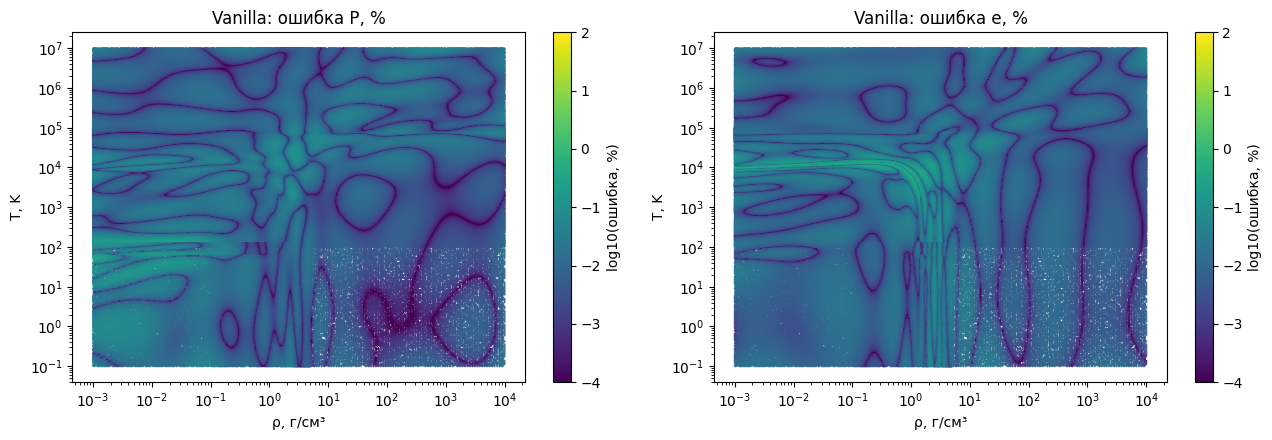

Сохранено: pinn-eos-aluminum/artifacts/figures/vanilla/vanilla_errors.png
region     rho         T        P   P_pred    err_P
 Obl01 0.00100 56.645388 0.153678 0.210169 0.367593
 Obl01 0.00103 56.645388 0.153703 0.208456 0.356225
 Obl01 0.00103 54.222210 0.129130 0.174431 0.350813
 Obl01 0.00106 56.645388 0.153731 0.206755 0.344912
 Obl01 0.00100 51.902691 0.108475 0.145014 0.336848


In [ ]:
# Тепловая карта ошибок Vanilla — аналог baseline_errors.png из 1.4
FIG = FIGURES / "vanilla"; FIG.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col, title in [(ax[0], 'err_P', 'Vanilla: ошибка P, %'),
                      (ax[1], 'err_e', 'Vanilla: ошибка e, %')]:
    sc = a.scatter(per_point['rho'], per_point['T'],
                   c=np.log10(per_point[col] + 1e-6),   # err уже в %, лог для контраста
                   s=0.3, cmap='viridis', vmin=-4, vmax=2, rasterized=True)
    a.set(xscale='log', yscale='log',
          xlabel='ρ, г/см³', ylabel='T, K', title=title)
    plt.colorbar(sc, ax=a, label='log10(ошибка, %)')

plt.tight_layout()
out = FIG / "vanilla_errors.png"
plt.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print("Сохранено:", out)

# Заодно — топ-5 ошибок: подтвердить гипотезу про шов T≈142 K
print(per_point.nlargest(5, 'err_P')[['region','rho','T','P','P_pred','err_P']].to_string(index=False))

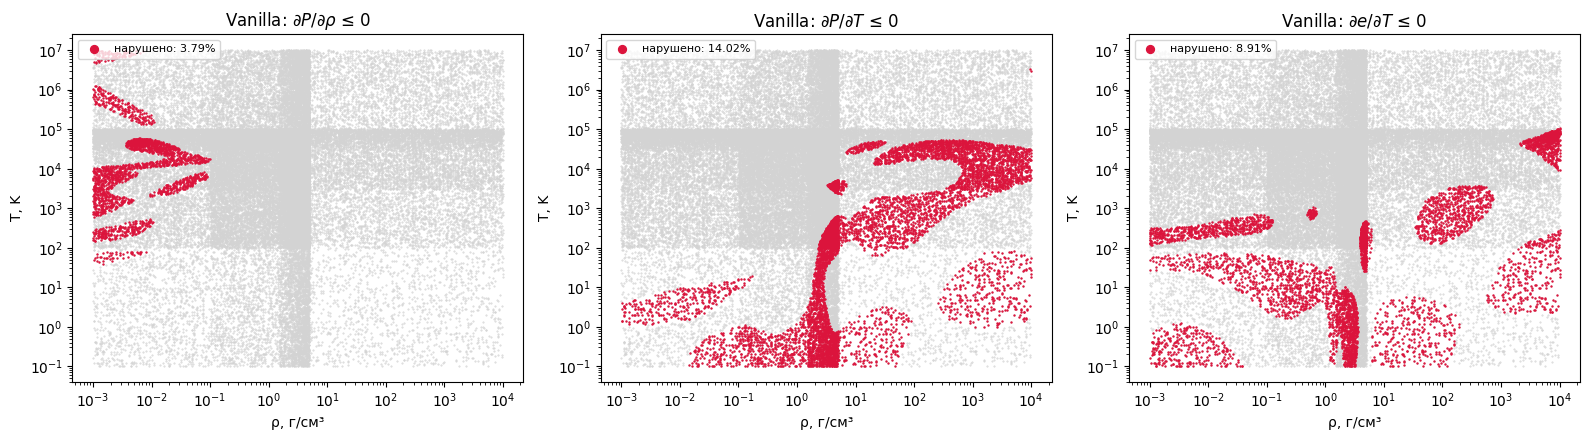

Сохранено: pinn-eos-aluminum/artifacts/figures/vanilla/vanilla_violations.png


In [ ]:
# Карта нарушений: пересчитываем производные на подвыборке test с координатами
rng = np.random.default_rng(0)
n_map = min(60_000, len(test_df))
sel = rng.choice(len(test_df), size=n_map, replace=False)
sub = test_df.iloc[sel].reset_index(drop=True)

dP_drho_m, dP_dT_m, de_dT_m = compute_derivatives(
    model, norm, sub['rho'].values, sub['T'].values, n_sample=n_map, seed=0)

rho_t = torch.tensor(sub['rho'].values, dtype=torch.float32, device=DEVICE, requires_grad=True)
T_t   = torch.tensor(sub['T'].values,   dtype=torch.float32, device=DEVICE, requires_grad=True)
P_t, e_t = norm.torch_inverse_y(model(norm.torch_x(rho_t, T_t)))
dP_drho_m = torch.autograd.grad(P_t.sum(), rho_t, retain_graph=True)[0].detach().cpu().numpy()
dP_dT_m   = torch.autograd.grad(P_t.sum(), T_t,   retain_graph=True)[0].detach().cpu().numpy()
de_dT_m   = torch.autograd.grad(e_t.sum(), T_t,   retain_graph=True)[0].detach().cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
panels = [
    (axes[0], dP_drho_m, r'$\partial P/\partial\rho$', 0),   # физично: > 0
    (axes[1], dP_dT_m,   r'$\partial P/\partial T$',   0),   # физично: > 0
    (axes[2], de_dT_m,   r'$\partial e/\partial T$',   0),   # физично: > 0
]
for ax, d, name, thresh in panels:
    bad = d <= thresh
    ax.scatter(sub['rho'], sub['T'], c='lightgray', s=0.2, rasterized=True)
    ax.scatter(sub['rho'][bad], sub['T'][bad], c='crimson', s=0.5, rasterized=True,
               label=f'нарушено: {100*bad.mean():.2f}%')
    ax.set(xscale='log', yscale='log', xlabel='ρ, г/см³', ylabel='T, K',
           title=f'Vanilla: {name} ≤ 0')
    ax.legend(loc='upper left', fontsize=8, markerscale=8)

plt.tight_layout()
out = FIG / "vanilla_violations.png"
plt.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print("Сохранено:", out)

---
## 3. Учёт физических ограничений (PINN) — Королева Ульяна (#3)

- [x] Физически ориентированная функция потерь: (∂P/∂ρ)_T > 0, (∂e/∂T)_ρ ≥ 0 (в данных при T ≲ 7 K плато), 0 < c_s < c
- [x] Согласованность (∂e/∂ρ)_T = (P − T ∂P/∂T)/ρ² проверена: её нарушает сама таблица, поэтому в loss не входит
- [x] Обучение PINN (256×4, GELU, 30 000 шагов)
- [x] Сравнение с базовой моделью по точности и нарушениям физики
- [x] Веса в `ARTIFACTS / 'pinn.pt'`


### 3.1 Физически ориентированная функция потерь

In [ ]:
# 3.1 Физически ориентированная функция потерь (код — src/eos/pinn.py)
import importlib, json, torch
import eos.normalize as nz, eos.model as em, eos.pinn as pn, eos.metrics as mt, eos.baseline as bl, eos.inference as inf
for m in (nz, em, mt, pn, bl, inf):
    importlib.reload(m)
pd.set_option('display.width', 250)
print('Устройство:', DEVICE)   # должно быть cuda — иначе включите GPU в настройках среды

norm = nz.EOSNormalizer.load(ARTIFACTS / 'normalization.json')
split = dict(np.load(ARTIFACTS / 'split.npz'))
test_df = df.iloc[split['test']]

def to_t(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32, device=DEVICE)

trainer = pn.Trainer(*(to_t(df[c].values) for c in ['rho', 'T', 'P', 'e']),
                     idx_train=torch.tensor(split['train'], device=DEVICE),
                     idx_val=torch.tensor(split['val'], device=DEVICE),
                     w_train=to_t(em.region_weights(df.iloc[split['train']])))

# Функция потерь PINN (производные — autograd по ln ρ и ln T, штрафы безразмерные):
#   L = MSE(данные)                                     — log10 P и asinh e после RobustScaler
#     + λ_ρ · mean max(0, −∂lnP/∂lnρ)                  — механическая устойчивость (∂P/∂ρ)_T > 0
#     + λ_T · mean max(0, −∂e/∂lnT) / (|e| + 1)         — термическая устойчивость (∂e/∂T)_ρ ≥ 0
#     + λ_c · mean нарушения 0 < c_s < c                 — скорость звука (3.3)
# Штрафы считаются в n_coll случайных точках по всей области (log ρ, log T); λ растут первые 20% шагов.
# Сеть 256×4, активация GELU (гладкая — производные сети входят в loss), градиенты — обычная сумма.
CFG = dict(hidden=256, layers=4, activation='gelu', loss='mse', grad='fixed',
           lam={'mono_rho': 1, 'mono_T': 1, 'sound': 1}, batch=8192, n_coll=1024, lr=2e-3)
STEPS = 30_000   # для пробного запуска поставьте 2000

# Штрафы на необученной сети (0 — условие выполнено во всех точках коллокации)
probe = em.EOSNet(norm, hidden=CFG['hidden'], layers=CFG['layers'], activation=CFG['activation']).to(DEVICE)
print('Штрафы на необученной сети:', {k: round(v.item(), 5) for k, v in trainer.physics_loss(probe, 4096).items()})

# Термодинамическая согласованность (∂e/∂ρ)_T = (P − T ∂P/∂T)/ρ² в loss не входит: её нарушает
# сама таблица (ratio_median = 0.5 в холодной части вместо 1), штраф спорил бы с данными
cons_table = pn.table_consistency(df)
cons_table.to_csv(ARTIFACTS / 'table_consistency.csv', index=False)
print(cons_table.to_string(index=False, float_format=lambda v: f'{v:.3g}'))

Устройство: cuda
Штрафы на необученной сети: {'cons': 0.75683, 'mono_rho': 0.00108, 'mono_T': 9e-05, 'sound': 0.31055}
region  cons_median  cons_p95  frac_gt_0.1_%  ratio_median
 Obl01        0.333     0.555           93.3           0.5
 Obl02       0.0167     0.174           16.3       0.00092
 Obl03     0.000223   0.00421              0         0.594
 Obl04     9.85e-05   0.00415              0          1.14
 Obl05     0.000649    0.0156              0        0.0689
 Obl06        0.333      0.46           99.5           0.5
 Obl07         0.24     0.434           83.1           0.5
 Obl08       0.0458     0.239           28.2          0.39
 Obl09       0.0126    0.0481         0.0622         0.475
 Obl10       0.0205    0.0892           1.06         0.414
 Obl11         0.68         1            100          0.19
 Obl12        0.646     0.975            100          0.19
 Obl13        0.418       0.7            100         0.156
 Obl14        0.118     0.262             56        0.0

### 3.2 Обучение PINN

  шаг   1000  train 1.025e-03  phys 2.382e-03  val 7.566e-04  11 с
  шаг   2000  train 3.922e-04  phys 2.569e-03  val 2.522e-04  22 с
  шаг   3000  train 3.606e-04  phys 2.705e-03  val 2.613e-04  33 с
  шаг   4000  train 3.811e-04  phys 2.878e-03  val 1.830e-04  44 с
  шаг   5000  train 2.510e-04  phys 2.432e-03  val 4.926e-04  55 с
  шаг   6000  train 1.553e-04  phys 1.939e-03  val 1.038e-04  66 с
  шаг   7000  train 1.194e-04  phys 1.598e-03  val 2.244e-04  77 с
  шаг   8000  train 1.108e-04  phys 1.474e-03  val 3.403e-05  88 с
  шаг   9000  train 5.927e-05  phys 8.697e-04  val 7.147e-05  99 с
  шаг  10000  train 5.911e-05  phys 1.155e-03  val 6.291e-05  110 с
  шаг  11000  train 7.269e-05  phys 1.169e-03  val 1.739e-04  121 с
  шаг  12000  train 5.322e-05  phys 8.992e-04  val 1.302e-04  132 с
  шаг  13000  train 4.191e-05  phys 6.840e-04  val 3.502e-05  142 с
  шаг  14000  train 6.123e-05  phys 1.337e-03  val 1.887e-05  153 с
  шаг  15000  train 5.098e-05  phys 9.268e-04  val 2.068e

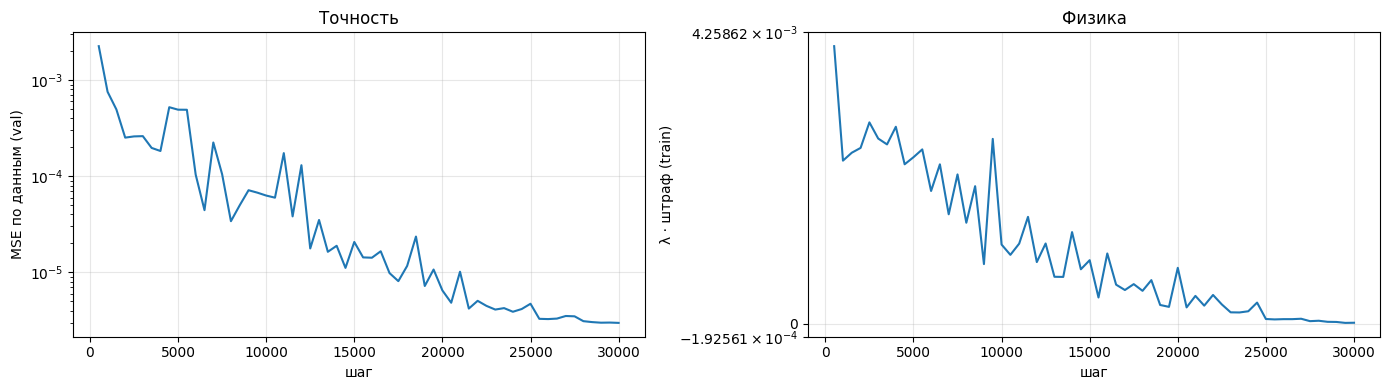

На GitHub: ecc9acf 3.2: PINN (GELU, MSE, штрафы ∂P/∂ρ, ∂e/∂T, c_s) — веса и кривая обучения
Файлы:
  artifacts/figures/pinn_learning_curve.png
  artifacts/figures/vanilla/vanilla_errors.png
  artifacts/figures/vanilla/vanilla_violations.png
  artifacts/pinn.pt


In [ ]:
# 3.2 Обучение PINN (прогресс печатается каждые 1000 шагов)
torch.manual_seed(0)
pinn = em.EOSNet(norm, hidden=CFG['hidden'], layers=CFG['layers'], activation=CFG['activation']).to(DEVICE)
hist = trainer.fit(pinn, lam=CFG['lam'], steps=STEPS, loss=CFG['loss'], grad=CFG['grad'],
                   batch=CFG['batch'], n_coll=CFG['n_coll'], lr=CFG['lr'])
print(f"Обучение: {hist['time_s'] / 60:.1f} мин, лучший val MSE {hist['best_val']:.3e}")
torch.save({'state_dict': pinn.state_dict(), 'config': pinn.config, 'train': CFG, 'steps': STEPS},
           ARTIFACTS / 'pinn.pt')

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(hist['step'], hist['val']); ax[0].set(yscale='log', xlabel='шаг', ylabel='MSE по данным (val)', title='Точность')
ax[1].plot(hist['step'], hist['phys']); ax[1].set(yscale='symlog', xlabel='шаг', ylabel='λ · штраф (train)', title='Физика')
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES / 'pinn_learning_curve.png', dpi=130, bbox_inches='tight')
plt.show()
save_to_repo('3.2: PINN (GELU, MSE, штрафы ∂P/∂ρ, ∂e/∂T, c_s) — веса и кривая обучения')

### 3.3 Ограничение на скорость звука 0 < c_s < c

Нарушение 0 < c_s < c: PINN 0.0000%, бейзлайн (таблица) 4.3910%


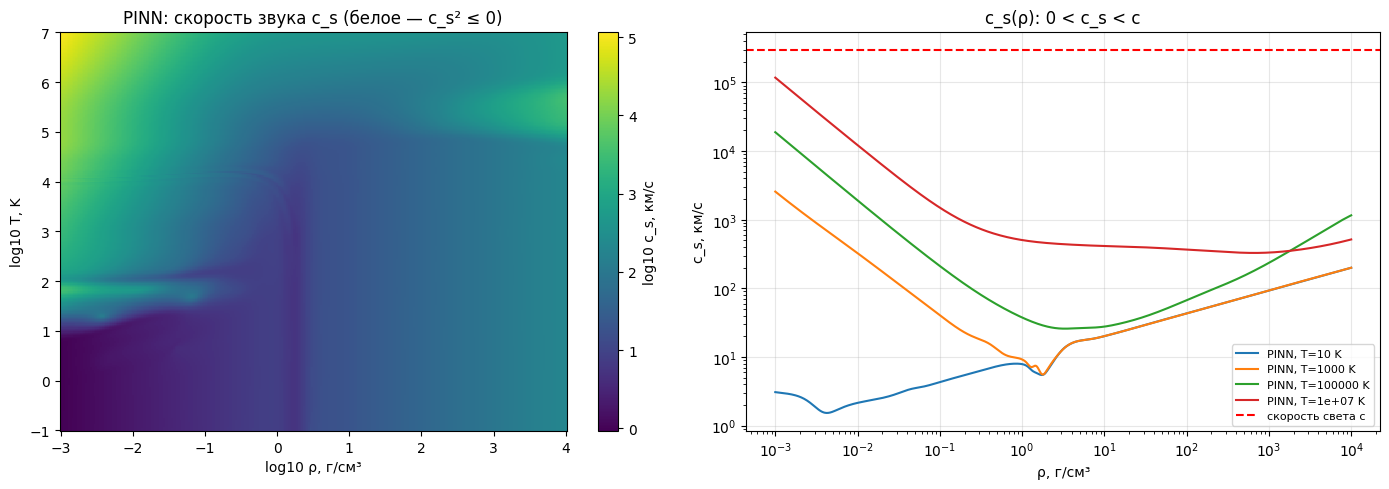

In [ ]:
# 3.3 Ограничение на скорость звука 0 < c_s < c (c — скорость света)
#   c_s² = (∂P/∂ρ)_T + T (∂P/∂T)_ρ² / (ρ² (∂e/∂T)_ρ);  в кДж/г = (км/с)²
# У PINN производные точные (autograd), у таблицы и бейзлайна — конечные разности
from eos.metrics import C_LIGHT_KMS
model_pinn = inf.EOSModel.from_net(pinn, device=DEVICE)

# Доля нарушений в 100 000 случайных точках всей области
rho_q, T_q = bl.random_queries(100_000, seed=1)
d = model_pinn._log_derivatives(rho_q, T_q)[0]
cs2_pinn = d['cs2']
baseline_full = bl.BilinearEOS(df)
viol_base = mt.physics_violations(baseline_full.predict, rho_q, T_q)['viol_cs_%']
print(f"Нарушение 0 < c_s < c: PINN {100 * np.mean(~((cs2_pinn > 0) & (cs2_pinn < C_LIGHT_KMS ** 2))):.4f}%, "
      f"бейзлайн (таблица) {viol_base:.4f}%")

# Карта c_s на плоскости (ρ, T) и срезы c_s(ρ) при фиксированных T
lr, lt = np.meshgrid(np.linspace(-3, 4, 300), np.linspace(-1, 7, 300))
cs_map = model_pinn.sound_speed(10 ** lr, 10 ** lt)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
im = ax[0].pcolormesh(lr, lt, np.log10(cs_map), cmap='viridis', shading='auto')
plt.colorbar(im, ax=ax[0], label='log10 c_s, км/с')
ax[0].set(xlabel='log10 ρ, г/см³', ylabel='log10 T, K', title='PINN: скорость звука c_s (белое — c_s² ≤ 0)')
rho_line = np.logspace(-3, 4, 600)
for k, Tv in enumerate([10.0, 1e3, 1e5, 1e7]):
    ax[1].plot(rho_line, model_pinn.sound_speed(rho_line, np.full_like(rho_line, Tv)), color=f'C{k}', label=f'PINN, T={Tv:g} K')
ax[1].axhline(C_LIGHT_KMS, color='r', ls='--', label='скорость света c')
ax[1].set(xscale='log', yscale='log', xlabel='ρ, г/см³', ylabel='c_s, км/с', title='c_s(ρ): 0 < c_s < c')
ax[1].grid(alpha=0.3); ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / 'pinn_sound_speed.png', dpi=130, bbox_inches='tight')
plt.show()

### 3.4 Сравнение с базовой моделью

model,Baseline (билинейная),Vanilla,PINN
err_P_median_%,0.0005,1.0260,0.2263
err_P_p99_%,0.0443,9.8000,2.5906
err_P_max_%,20.3873,36.7593,21.6672
err_e_median_%,0.0040,1.1579,0.2454
err_e_p99_%,0.1683,27.8355,3.1680
err_e_max_%,13.6153,77.1548,19.7062
viol_dP_drho_%,0.0473,4.8405,0.0000
viol_de_dT_%,0.4572,10.6902,0.0000
viol_cs_%,0.7867,NaN,0.0000
viol_dP_dT_%,0.7414,13.1152,10.1657


Физика PINN через autograd (100 000 случайных точек):
autograd_viol_dP_drho_%          0.0000
autograd_viol_de_dT_%            0.0000
autograd_viol_cs2_%              0.0000
autograd_viol_superluminal_%     0.0000
autograd_viol_cons_gt_0.1_%     66.0490
autograd_cons_median             0.3302


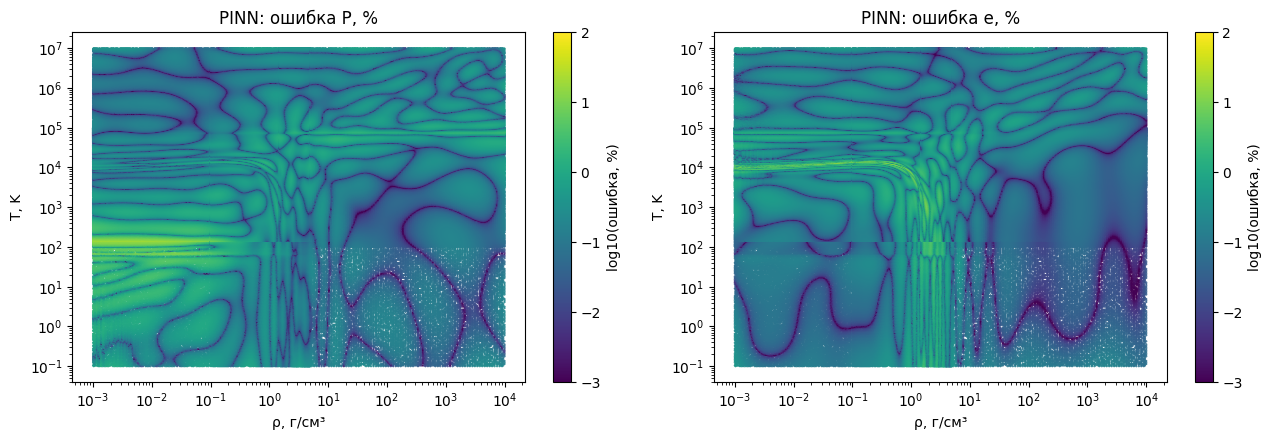

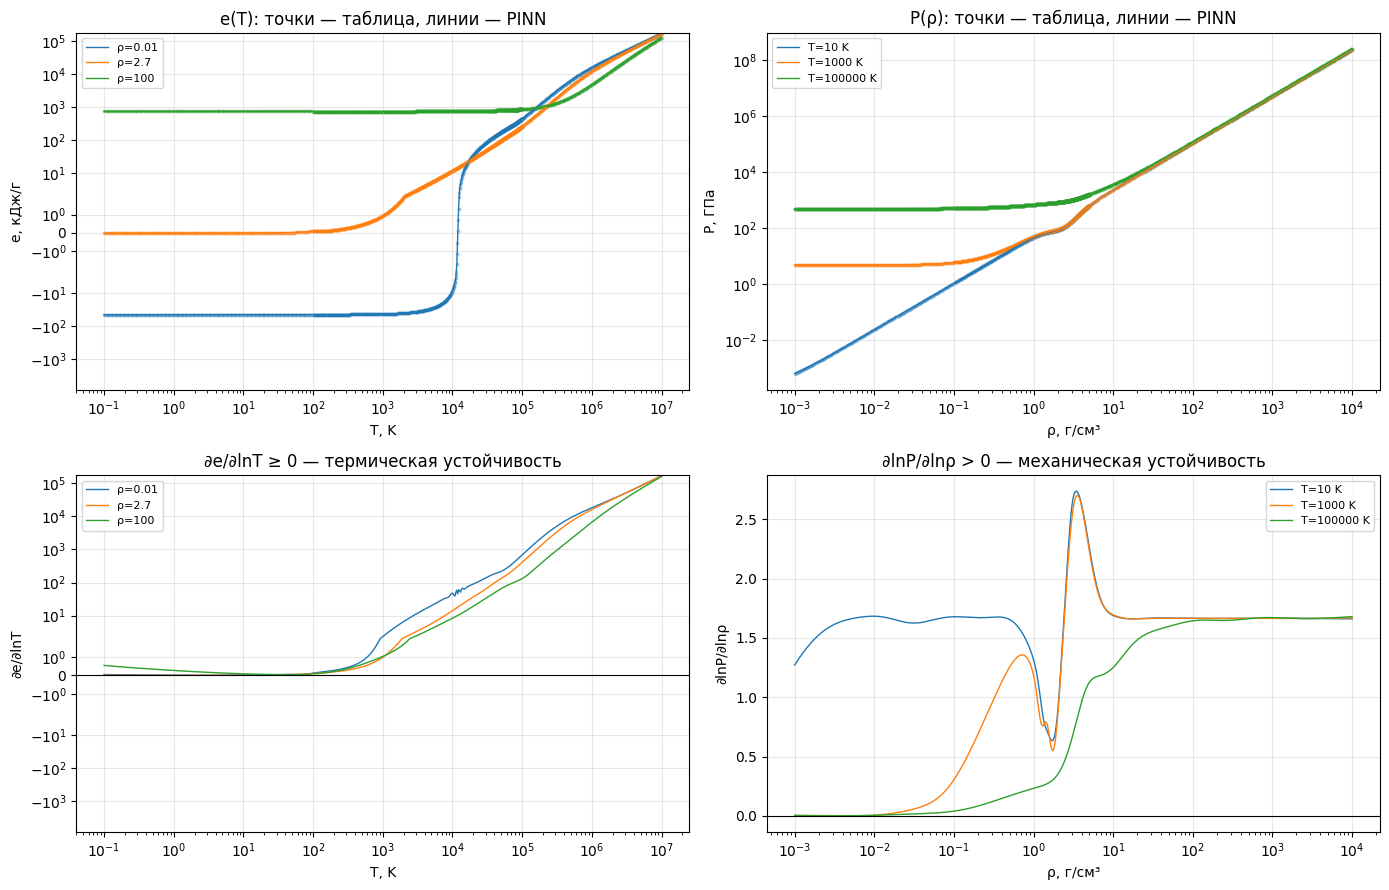

На GitHub: 56808d4 3.3–3.4: PINN — скорость звука, метрики на test, карта ошибок, сечения
Файлы:
  artifacts/figures/pinn_errors.png
  artifacts/figures/pinn_sections.png
  artifacts/figures/pinn_sound_speed.png
  artifacts/metrics_compare.csv
  artifacts/metrics_pinn.json


In [ ]:
# 3.4 Сравнение с базовой моделью: точность и нарушения физики на одном test (функция mt.evaluate)


class TorchEOS:
    """Обёртка для замера скорости: float32 на DEVICE, как в рабочем инференсе."""

    def __init__(self, model):
        self.model = model.eval()

    @torch.no_grad()
    def predict(self, rho, T):
        P, e = self.model(to_t(rho), to_t(T))
        return P.cpu().numpy(), e.cpu().numpy()


metrics, per_point = mt.evaluate(pn.numpy_predict(pinn), test_df, 'PINN')
metrics['time_1e5_s'] = bl.benchmark(TorchEOS(pinn), n=100_000)
metrics['size_MB'] = sum(p.numel() for p in pinn.parameters()) * 4 / 2**20
metrics.update({f'autograd_{k}': v for k, v in pn.physics_report(pinn, n=100_000).items()})
with open(ARTIFACTS / 'metrics_pinn.json', 'w') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

# Бейзлайн пересчитываем (быстро), чтобы в его метриках было и нарушение скорости звука
with open(ARTIFACTS / 'metrics_baseline.json') as f:
    base_old = json.load(f)
base_met, _ = mt.evaluate(bl.BilinearEOS(df, decimate=True).predict, test_df, 'Baseline (билинейная)')
base_met.update({k: base_old[k] for k in ('time_1e5_s', 'size_MB')})
rows = [base_met]
if (ARTIFACTS / 'metrics_vanilla.json').exists():          # Vanilla — из раздела 2 (без viol_cs_%)
    with open(ARTIFACTS / 'metrics_vanilla.json') as f:
        rows.append(json.load(f))
rows.append(metrics)
keys = ['err_P_median_%', 'err_P_p99_%', 'err_P_max_%', 'err_e_median_%', 'err_e_p99_%', 'err_e_max_%',
        'viol_dP_drho_%', 'viol_de_dT_%', 'viol_cs_%', 'viol_dP_dT_%', 'time_1e5_s', 'size_MB']
compare = pd.DataFrame(rows).set_index('model')
compare.to_csv(ARTIFACTS / 'metrics_compare.csv')
display(compare[keys].T.round(4))
print('Физика PINN через autograd (100 000 случайных точек):')
print(pd.Series({k: v for k, v in metrics.items() if k.startswith('autograd_')}).round(4).to_string())

# Карта ошибок на (ρ, T)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col, title in [(ax[0], 'err_P', 'ошибка P, %'), (ax[1], 'err_e', 'ошибка e, %')]:
    sc = a.scatter(per_point['rho'], per_point['T'], c=np.log10(per_point[col] * 100 + 1e-6), s=0.3,
                   cmap='viridis', vmin=-3, vmax=2, rasterized=True)
    a.set(xscale='log', yscale='log', xlabel='ρ, г/см³', ylabel='T, K', title=f'PINN: {title}')
    plt.colorbar(sc, ax=a, label='log10(ошибка, %)')
plt.tight_layout()
plt.savefig(FIGURES / 'pinn_errors.png', dpi=130, bbox_inches='tight')
plt.show()


def section(col, v):
    """Точки таблицы при col ≈ v: в каждой области свой ближайший узел (сетки разные)."""
    parts = []
    for _, g in df.groupby('region'):
        u = np.unique(g[col])
        k = np.abs(np.log(u / v)).argmin()
        if abs(np.log(u[k] / v)) < 0.02:
            parts.append(g[g[col] == u[k]])
    return pd.concat(parts)


# Сечения: таблица (точки) и PINN (линии); внизу — знак производных
predict = pn.numpy_predict(pinn)
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
T_line, rho_line = np.logspace(-1, 7, 600), np.logspace(-3, 4, 600)
for k, rv in enumerate([0.01, 2.7, 100.0]):
    pts, r_ = section('rho', rv), np.full_like(T_line, rv)
    ax[0, 0].scatter(pts['T'], pts['e'], s=3, color=f'C{k}', alpha=0.3)
    ax[0, 0].plot(T_line, predict(r_, T_line)[1], color=f'C{k}', lw=1, label=f'ρ={rv:g}')
    d = pn.log_derivatives(pinn, to_t(r_), to_t(T_line), create_graph=False)
    ax[1, 0].plot(T_line, d['e_t'].detach().cpu().numpy(), color=f'C{k}', lw=1, label=f'ρ={rv:g}')
for k, Tv in enumerate([10.0, 1e3, 1e5]):
    pts, T_ = section('T', Tv), np.full_like(rho_line, Tv)
    ax[0, 1].scatter(pts['rho'], pts['P'], s=3, color=f'C{k}', alpha=0.3)
    ax[0, 1].plot(rho_line, predict(rho_line, T_)[0], color=f'C{k}', lw=1, label=f'T={Tv:g} K')
    d = pn.log_derivatives(pinn, to_t(rho_line), to_t(T_), create_graph=False)
    ax[1, 1].plot(rho_line, d['a'].detach().cpu().numpy(), color=f'C{k}', lw=1, label=f'T={Tv:g} K')
ax[0, 0].set(xscale='log', yscale='symlog', xlabel='T, K', ylabel='e, кДж/г', title='e(T): точки — таблица, линии — PINN')
ax[0, 1].set(xscale='log', yscale='log', xlabel='ρ, г/см³', ylabel='P, ГПа', title='P(ρ): точки — таблица, линии — PINN')
ax[1, 0].set(xscale='log', yscale='symlog', xlabel='T, K', ylabel='∂e/∂lnT', title='∂e/∂lnT ≥ 0 — термическая устойчивость')
ax[1, 1].set(xscale='log', xlabel='ρ, г/см³', ylabel='∂lnP/∂lnρ', title='∂lnP/∂lnρ > 0 — механическая устойчивость')
for a in ax.ravel():
    a.grid(alpha=0.3); a.legend(fontsize=8)
ax[1, 0].axhline(0, color='k', lw=0.8); ax[1, 1].axhline(0, color='k', lw=0.8)
plt.tight_layout()
plt.savefig(FIGURES / 'pinn_sections.png', dpi=130, bbox_inches='tight')
plt.show()

save_to_repo('3.3–3.4: PINN — скорость звука, метрики на test, карта ошибок, сечения')

---
## 4. Инференс, упаковка и сжатие — Володченко Александра (#4)

- [x] Класс `EOSModel`: `predict`, `sound_speed`, `check_physics`
- [x] Размер модели (≤ 10 МБ), время на 10⁵ запросов (CPU и GPU)
- [x] Экспорт TorchScript / ONNX
- [x] Сжатие: квантизация / меньшая сеть
- [x] Единая таблица сравнения baseline / Vanilla / PINN

### 4.1 Класс-обёртка

In [ ]:
# 4.1 Класс-обёртка EOSModel (код — src/eos/inference.py): predict, sound_speed, check_physics
import importlib, json, time, torch
import eos.normalize as nz, eos.model as em, eos.pinn as pn, eos.metrics as mt, eos.baseline as bl, eos.inference as inf
for m in (nz, em, pn, mt, bl, inf):
    importlib.reload(m)
pd.set_option('display.width', 250)

MODEL = ARTIFACTS / 'pinn.pt'
NORM = ARTIFACTS / 'normalization.json'
model = inf.EOSModel(MODEL, NORM, device=DEVICE)                          # float32 — быстрый
model64 = inf.EOSModel(MODEL, NORM, device=DEVICE, dtype=torch.float64)   # float64 — для метрик
print('Конфигурация сети:', model.net.config)

# Примеры: обычный алюминий, сжатый горячий, разреженная плазма
rho_ex = np.array([2.7, 10.0, 0.01, 1000.0])
T_ex = np.array([300.0, 1e4, 1e6, 1e5])
P_ex, e_ex = model.predict(rho_ex, T_ex)
flags = model.check_physics(rho_ex, T_ex)
display(pd.DataFrame({'ρ, г/см³': rho_ex, 'T, K': T_ex, 'P, ГПа': P_ex, 'e, кДж/г': e_ex,
                      'c_s, км/с': model.sound_speed(rho_ex, T_ex),
                      **{k: v for k, v in flags.items() if k != 'cons_residual'}}))

# Проверка физики на 100 000 случайных точках всей области (ρ, T)
rho_q, T_q = bl.random_queries(100_000, seed=1)
flags = model.check_physics(rho_q, T_q)
print('Доля точек, где условие выполнено, %:')
print(pd.Series({k: 100 * v.mean() for k, v in flags.items() if k != 'cons_residual'}).round(3).to_string())

Конфигурация сети: {'hidden': 256, 'layers': 4, 'activation': 'gelu'}


,"ρ, г/см³","T, K","P, ГПа","e, кДж/г","c_s, км/с",mechanical,thermal,sound,consistent,in_domain
0,2.70,300.0,1.365550e+02,0.267279,10.577020,True,True,True,False,True
1,10.00,10000.0,2.444551e+03,86.226753,20.098199,True,True,True,False,True
2,0.01,1000000.0,5.084953e+03,15633.445312,3765.071363,True,True,True,True,True
3,1000.00,100000.0,5.613321e+06,3849.761230,235.258209,True,True,True,True,True


Доля точек, где условие выполнено, %:
mechanical    100.000
thermal       100.000
sound         100.000
consistent     33.933
in_domain     100.000


### 4.2 Размер и скорость

In [ ]:
# 4.2 Размер модели и время на 10^5 запросов (CPU и GPU)
size = {'файл pinn.pt, МБ': MODEL.stat().st_size / 2**20,
        'параметров': sum(p.numel() for p in model.net.parameters())}
print(pd.Series(size).to_string(), '\nЛимит по заданию: 10 МБ')

speed = {}
for dev in ['cpu'] + (['cuda'] if torch.cuda.is_available() else []):
    for dt in (torch.float32, torch.float64):
        mm = inf.EOSModel(MODEL, NORM, device=dev, dtype=dt)
        speed[f'PINN {dev} {str(dt)[6:]}'] = bl.benchmark(mm, n=100_000)   # лучшее из 5 прогонов
baseline = bl.BilinearEOS(df)
speed['Бейзлайн (билинейная, CPU)'] = bl.benchmark(baseline, n=100_000)
speed = pd.Series(speed, name='время на 10^5 запросов, с')
display(speed.round(4).to_frame())
with open(ARTIFACTS / 'metrics_speed.json', 'w') as f:
    json.dump({**size, **speed.to_dict()}, f, indent=2, ensure_ascii=False)

файл pinn.pt, МБ         0.761617
параметров          198658.000000 
Лимит по заданию: 10 МБ


,"время на 10^5 запросов, с"
PINN cpu float32,0.7760
PINN cpu float64,2.2367
PINN cuda float32,0.0225
PINN cuda float64,0.2317
"Бейзлайн (билинейная, CPU)",0.0596


### 4.3 Экспорт

In [ ]:
# 4.3 Экспорт: TorchScript и ONNX (нормировка зашита внутрь — вход ρ, T, выход P, e)
import subprocess, sys
try:
    import onnx, onnxruntime
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'onnx', 'onnxruntime'], check=True)

TS_PATH, ONNX_PATH = ARTIFACTS / 'pinn_torchscript.pt', ARTIFACTS / 'pinn.onnx'
ts = inf.export_torchscript(model.net, TS_PATH)
inf.export_onnx(model.net, ONNX_PATH)
onnx_model = inf.OnnxEOS(ONNX_PATH)

# Совпадают ли ответы экспортированных моделей с исходной (float64)
P0, e0 = model64.predict(rho_q, T_q)
with torch.no_grad():
    P_ts, e_ts = (x.numpy() for x in ts(torch.tensor(rho_q, dtype=torch.float32),
                                         torch.tensor(T_q, dtype=torch.float32)))
P_ox, e_ox = onnx_model.predict(rho_q, T_q)
rel = lambda P, e: (np.max(np.abs(P / P0 - 1)), np.max(np.abs(e - e0) / np.maximum(np.abs(e0), 1)))
export = pd.DataFrame({
    'TorchScript': [TS_PATH.stat().st_size / 2**20, *rel(P_ts, e_ts), np.nan],
    'ONNX': [ONNX_PATH.stat().st_size / 2**20, *rel(P_ox, e_ox), bl.benchmark(onnx_model, n=100_000)],
}, index=['размер, МБ', 'макс. отн. отличие P', 'макс. отличие e (как в метрике)', 'время 10^5 (ONNX Runtime, CPU), с'])
display(export.T)
print('Загрузка без нашего кода: torch.jit.load(path)(rho, T)  или  onnxruntime.InferenceSession(path)')

,"размер, МБ",макс. отн. отличие P,макс. отличие e (как в метрике),"время 10^5 (ONNX Runtime, CPU), с"
TorchScript,0.783016,0.000018,0.000048,NaN
ONNX,0.763824,0.000018,0.000051,0.516214


Загрузка без нашего кода: torch.jit.load(path)(rho, T)  или  onnxruntime.InferenceSession(path)


### 4.4 Сжатие

In [ ]:
# 4.4 Сжатие: float16, int8 (динамическая квантизация), int8 только весов. Точность — на общем test
test_df = df.iloc[np.load(ARTIFACTS / 'split.npz')['test']]

FP16_PATH, INT8W_PATH = ARTIFACTS / 'pinn_fp16.pt', ARTIFACTS / 'pinn_int8w.pt'
inf.save_fp16(model.net, FP16_PATH)
net_w8, packed = inf.compress_int8_weights(model.net)
inf.save_int8_weights(net_w8, packed, INT8W_PATH)
net_q8 = inf.compress_int8(model.net)
q8_buf = ARTIFACTS / 'pinn_int8_dynamic.pt'
torch.save(net_q8.state_dict(), q8_buf)

variants = {
    'PINN float32 (исходная)': (model64, MODEL),
    'PINN float16': (inf.EOSModel(FP16_PATH, NORM, device=DEVICE, dtype=torch.float64), FP16_PATH),
    'PINN int8 (только веса)': (inf.EOSModel.from_net(inf.load_int8_weights(INT8W_PATH, NORM), device=DEVICE,
                                                     dtype=torch.float64), INT8W_PATH),
    'PINN int8 (динамическая, CPU)': (inf.EOSModel.from_net(net_q8), q8_buf),
}
rows = []
for name, (mm, path) in variants.items():
    met, _ = mt.evaluate(mm.predict, test_df, name)
    met['size_MB'] = path.stat().st_size / 2**20
    rows.append(met)
compress = pd.DataFrame(rows).set_index('model')
compress.to_csv(ARTIFACTS / 'metrics_compression.csv')
display(compress[['size_MB', 'err_P_median_%', 'err_P_p99_%', 'err_e_median_%', 'err_e_p99_%',
                  'viol_dP_drho_%', 'viol_de_dT_%']].round(4))
q8_buf.unlink()   # динамическая int8 непригодна (см. таблицу) — в репозиторий не кладём

,size_MB,err_P_median_%,err_P_p99_%,err_e_median_%,err_e_p99_%,viol_dP_drho_%,viol_de_dT_%
model,,,,,,,
PINN float32 (исходная),0.7616,0.2263,2.5906,0.2454,3.1680,0.0000,0.0000
PINN float16,0.3828,0.2309,2.5885,0.2525,3.1577,0.0000,0.0000
PINN int8 (только веса),0.1976,1.2762,5.9366,4.2847,10.7702,0.1033,2.3077
"PINN int8 (динамическая, CPU)",0.1997,10.6781,46.6936,27.9046,246.8644,39.4666,62.6184


### 4.5 Таблица сравнения

In [ ]:
# 4.5 Единая таблица сравнения baseline / Vanilla / PINN (+ сжатая PINN) — на одном test
rows = []
for name in ['metrics_baseline.json', 'metrics_vanilla.json']:
    with open(ARTIFACTS / name) as f:
        rows.append(json.load(f))
pinn_met, _ = mt.evaluate(model64.predict, test_df, 'PINN')
pinn_met['size_MB'] = MODEL.stat().st_size / 2**20
fp16_met = compress.loc['PINN float16'].to_dict() | {'model': 'PINN float16'}
gpu = 'PINN cuda float32' if 'PINN cuda float32' in speed else 'PINN cpu float32'
pinn_met['time_1e5_s'] = fp16_met['time_1e5_s'] = speed[gpu]
pinn_met['time_cpu_1e5_s'] = fp16_met['time_cpu_1e5_s'] = speed['PINN cpu float32']
rows += [pinn_met, fp16_met]

final = pd.DataFrame(rows).set_index('model')
base_row = final.index.str.startswith('Baseline')            # бейзлайн считается только на CPU
final.loc[base_row, 'time_cpu_1e5_s'] = final.loc[base_row, 'time_1e5_s']
cols = {'err_P_median_%': 'ошибка P, медиана %', 'err_P_p99_%': 'ошибка P, p99 %',
        'err_e_median_%': 'ошибка e, медиана %', 'err_e_p99_%': 'ошибка e, p99 %',
        'viol_dP_drho_%': '∂P/∂ρ ≤ 0, %', 'viol_de_dT_%': '∂e/∂T < 0, %',
        'size_MB': 'размер, МБ', 'time_1e5_s': 'время 10^5, с (сети — GPU, бейзлайн — CPU)',
        'time_cpu_1e5_s': 'время 10^5 на CPU, с'}
table = final[list(cols)].rename(columns=cols)
table.to_csv(ARTIFACTS / 'metrics_final.csv')
try:
    md = table.to_markdown(floatfmt='.4g')            # таблица для README и отчёта
    (ARTIFACTS / 'metrics_final.md').write_text(md)
except ImportError:
    print('Для metrics_final.md нужен пакет tabulate: pip install tabulate')
display(table.T.round(4))
print('Нарушения у Vanilla посчитаны во float32 (раздел 2) — часть из них шум округления.')
save_to_repo('4: EOSModel, скорость, экспорт TorchScript/ONNX, сжатие, итоговая таблица')

model,Baseline (билинейная),Vanilla,PINN,PINN float16
"ошибка P, медиана %",0.0005,1.0260,0.2263,0.2309
"ошибка P, p99 %",0.0443,9.8000,2.5906,2.5885
"ошибка e, медиана %",0.0040,1.1579,0.2454,0.2525
"ошибка e, p99 %",0.1683,27.8355,3.1680,3.1577
"∂P/∂ρ ≤ 0, %",0.0473,4.8405,0.0000,0.0000
"∂e/∂T < 0, %",0.4572,10.6902,0.0000,0.0000
"размер, МБ",34.4865,0.7620,0.7616,0.3828
"время 10^5, с (сети — GPU, бейзлайн — CPU)",0.0667,0.0234,0.0225,0.0225
"время 10^5 на CPU, с",0.0667,NaN,0.7760,0.7760


Нарушения у Vanilla посчитаны во float32 (раздел 2) — часть из них шум округления.
На GitHub: ada32c6 4: EOSModel, скорость, экспорт TorchScript/ONNX, сжатие, итоговая таблица
Файлы:
  artifacts/metrics_compression.csv
  artifacts/metrics_final.csv
  artifacts/metrics_final.md
  artifacts/metrics_speed.json
  artifacts/pinn.onnx
  artifacts/pinn_fp16.pt
  artifacts/pinn_int8w.pt
  artifacts/pinn_torchscript.pt


---
## 5. Сжатие и скорость работы (дополнительный этап) — Селивохин Ярослав (#5)

- [x] Исходная точка: размер, время на CPU и GPU, точность PINN 256×4
- [x] Дистилляция в сети 128×4 и 64×4 (учитель — PINN 256×4)
- [x] Измеримый эффект: float16, ONNX Runtime, смешанная точность на GPU
- [x] SVD-сжатие внутренних слоёв 256→256 (r = 64, 32) + дообучение с физическими штрафами


### 5.1 Исходная точка

In [15]:
# 5.1 Исходная точка: PINN 256×4 из раздела 3 — размер, скорость, точность
import importlib, json, subprocess, sys, torch
import eos.normalize as nz, eos.model as em, eos.pinn as pn, eos.metrics as mt, eos.baseline as bl, eos.inference as inf
for m in (nz, em, mt, pn, bl, inf):
    importlib.reload(m)
try:
    import onnx, onnxruntime
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'onnx', 'onnxruntime'], check=True)
pd.set_option('display.width', 250)

NORM = ARTIFACTS / 'normalization.json'
split = dict(np.load(ARTIFACTS / 'split.npz'))
test_df = df.iloc[split['test']]
teacher = inf.load_eosnet(ARTIFACTS / 'pinn.pt', NORM, device=DEVICE)
for p in teacher.parameters():
    p.requires_grad_(False)

def flops_per_query(net):
    """Умножений-сложений на один запрос (по слоям Linear) — от этого зависит время на CPU."""
    return sum(2 * m.in_features * m.out_features for m in net.modules() if isinstance(m, torch.nn.Linear))

with open(ARTIFACTS / 'metrics_pinn.json') as f:
    start = json.load(f)
cpu_start = bl.benchmark(inf.EOSModel(ARTIFACTS / 'pinn.pt', NORM, device='cpu'), n=100_000)
print(f"PINN {teacher.config}: файл {(ARTIFACTS / 'pinn.pt').stat().st_size / 2**20:.3f} МБ, "
      f"{flops_per_query(teacher) / 1e3:.0f} тыс. операций на запрос")
print(f"Время на 10^5 запросов: CPU {cpu_start:.3f} с, GPU {start['time_1e5_s']:.4f} с; "
      f"ошибка P {start['err_P_median_%']:.3f}%, e {start['err_e_median_%']:.3f}% (медианы)")
print('Почти всё время на CPU — умножение матриц 256×256: его и уменьшаем (5.2), плюс ускоряем сам расчёт (5.3)')

PINN {'hidden': 256, 'layers': 4, 'activation': 'gelu'}: файл 0.762 МБ, 395 тыс. операций на запрос
Время на 10^5 запросов: CPU 0.817 с, GPU 0.0128 с; ошибка P 0.226%, e 0.245% (медианы)
Почти всё время на CPU — умножение матриц 256×256: его и уменьшаем (5.2), плюс ускоряем сам расчёт (5.3)


### 5.2 Дистилляция в меньшие сети

In [16]:
# 5.2 Дистилляция: маленькие сети учатся у PINN 256×4 (учитель) + те же физические штрафы.
# Учитель даёт ответы в любых точках области, поэтому ученик учится и между узлами таблицы
STUDENTS = {'pinn_128x4': (128, 4), 'pinn_64x4': (64, 4)}
STEPS_KD = 3000                       # для пробного запуска — 3000
LAM = {'mono_rho': 1, 'mono_T': 1, 'sound': 1}

def to_t(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32, device=DEVICE)

trainer = pn.Trainer(*(to_t(df[c].values) for c in ['rho', 'T', 'P', 'e']),
                     idx_train=torch.tensor(split['train'], device=DEVICE),
                     idx_val=torch.tensor(split['val'], device=DEVICE),
                     w_train=to_t(em.region_weights(df.iloc[split['train']])))
students = {}
for name, (hidden, layers) in STUDENTS.items():
    print(f'=== {name}: {hidden}×{layers}')
    torch.manual_seed(0)
    net = em.EOSNet(teacher.norm, hidden=hidden, layers=layers, activation='gelu').to(DEVICE)
    hist = trainer.fit(net, lam=LAM, steps=STEPS_KD, n_coll=1024, teacher=teacher)
    inf.save_net(net, ARTIFACTS / f'{name}.pt')
    students[name] = net
    print(f"    обучение {hist['time_s'] / 60:.1f} мин")
save_to_repo('5.2: дистилляция PINN в сети 128×4 и 64×4')

=== pinn_128x4: 128×4
  шаг   1000  train 2.280e-03  phys 6.562e-03  val 1.596e-03  14 с
  шаг   2000  train 9.884e-04  phys 2.127e-03  val 8.894e-04  29 с
  шаг   3000  train 7.560e-04  phys 1.529e-03  val 7.415e-04  42 с
    обучение 0.7 мин
=== pinn_64x4: 64×4
  шаг   1000  train 4.612e-03  phys 9.111e-03  val 2.458e-03  13 с
  шаг   2000  train 2.179e-03  phys 5.103e-03  val 1.796e-03  27 с
  шаг   3000  train 1.825e-03  phys 4.305e-03  val 1.691e-03  41 с
    обучение 0.7 мин
На GitHub: aaf7f67 5.2: дистилляция PINN в сети 128×4 и 64×4
Файлы:
  artifacts/pinn_128x4.pt
  artifacts/pinn_64x4.pt


### 5.3 Измеримый эффект оптимизации

модель,Бейзлайн (таблица),PINN 256×4,PINN 128×4 (дистилл.),PINN 64×4 (дистилл.)
"файл float32, МБ",34.4865,0.7617,0.1953,0.0527
err_P_median_%,0.0005,0.2309,3.6486,5.7236
err_P_p99_%,0.0443,2.5885,29.7410,38.4951
err_e_median_%,0.0040,0.2525,4.1503,3.8035
err_e_p99_%,0.1683,3.1577,106.1416,128.2665
viol_dP_drho_%,0.0473,0.0000,0.0344,0.0702
viol_de_dT_%,0.4572,0.0000,0.0584,0.2859
"CPU torch, с",0.0667,0.8158,0.3499,0.1352
параметров,NaN,198658.0000,50178.0000,12802.0000
"файл float16, МБ",NaN,0.3829,0.0997,0.0284


Эффект оптимизации (относительно PINN 256×4, float32, CPU torch):
  PINN 256×4               размер ×2.0 меньше, CPU ×1.5 быстрее, ошибка P 0.231% (было 0.231%)
  PINN 128×4 (дистилл.)    размер ×7.6 меньше, CPU ×4.5 быстрее, ошибка P 3.649% (было 0.231%)
  PINN 64×4 (дистилл.)     размер ×26.8 меньше, CPU ×9.9 быстрее, ошибка P 5.724% (было 0.231%)


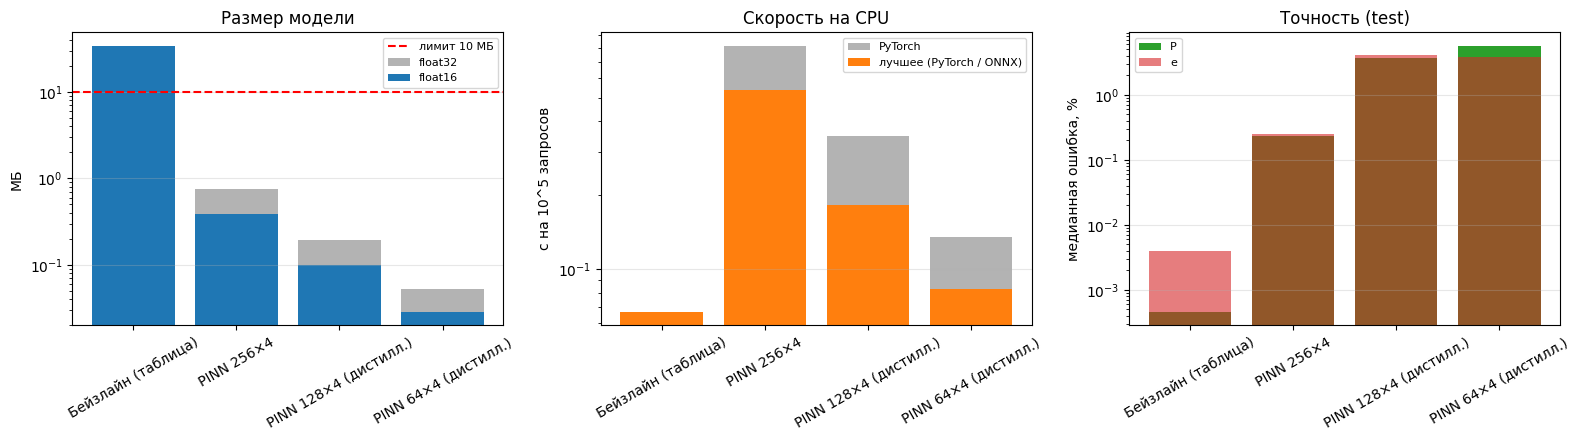

На GitHub: 9e964dd 5.3: оптимизация — размер, скорость, точность
Файлы:
  artifacts/figures/optimization.png
  artifacts/metrics_optimization.csv
  artifacts/optimized/pinn_128x4.onnx
  artifacts/optimized/pinn_128x4.pt
  artifacts/optimized/pinn_128x4_fp16.pt
  artifacts/optimized/pinn_256x4.onnx
  artifacts/optimized/pinn_256x4.pt
  artifacts/optimized/pinn_256x4_fp16.pt
  artifacts/optimized/pinn_64x4.onnx
  artifacts/optimized/pinn_64x4.pt
  artifacts/optimized/pinn_64x4_fp16.pt


In [17]:
# 5.3 Измеримый эффект оптимизаций: размер, скорость (CPU / GPU), точность и физика на test
(ARTIFACTS / 'optimized').mkdir(exist_ok=True)
nets = {'PINN 256×4': teacher, 'PINN 128×4 (дистилл.)': students['pinn_128x4'],
        'PINN 64×4 (дистилл.)': students['pinn_64x4']}
rows = []
for name, net in nets.items():
    tag = name.split()[1].replace('×', 'x')
    fp16_path = ARTIFACTS / 'optimized' / f'pinn_{tag}_fp16.pt'
    onnx_path = ARTIFACTS / 'optimized' / f'pinn_{tag}.onnx'
    row = {'модель': name, 'параметров': sum(p.numel() for p in net.parameters()),
           'файл float32, МБ': inf.save_net(net, ARTIFACTS / 'optimized' / f'pinn_{tag}.pt'),
           'файл float16, МБ': inf.save_net(net, fp16_path, fp16=True)}
    # точность и нарушения — у float16-версии (её и отдаём), считаем во float64
    model16 = inf.EOSModel(fp16_path, NORM, device=DEVICE, dtype=torch.float64)
    met, _ = mt.evaluate(model16.predict, test_df, name)
    row.update({k: met[k] for k in ['err_P_median_%', 'err_P_p99_%', 'err_e_median_%', 'err_e_p99_%',
                                    'viol_dP_drho_%', 'viol_de_dT_%', 'viol_cs_%']})
    # скорость на 10^5 запросов
    row['CPU torch, с'] = bl.benchmark(inf.EOSModel(fp16_path, NORM, device='cpu'), n=100_000)
    inf.export_onnx(net, onnx_path)
    row['CPU ONNX Runtime, с'] = bl.benchmark(inf.OnnxEOS(onnx_path), n=100_000)
    if torch.cuda.is_available():
        row['GPU float32, с'] = bl.benchmark(inf.EOSModel(fp16_path, NORM, device='cuda'), n=100_000)
        fast = inf.GpuFp16EOS(net)
        row['GPU float16, с'] = bl.benchmark(fast, n=100_000)
        m16, _ = mt.evaluate(fast.predict, test_df.iloc[::10], name)   # точность при счёте во float16
        row['GPU float16: ошибка P, медиана %'] = m16['err_P_median_%']
    rows.append(row)

with open(ARTIFACTS / 'metrics_baseline.json') as f:
    base = json.load(f)
rows.insert(0, {'модель': 'Бейзлайн (таблица)', 'файл float32, МБ': base['size_MB'],
                'err_P_median_%': base['err_P_median_%'], 'err_P_p99_%': base['err_P_p99_%'],
                'err_e_median_%': base['err_e_median_%'], 'err_e_p99_%': base['err_e_p99_%'],
                'viol_dP_drho_%': base['viol_dP_drho_%'], 'viol_de_dT_%': base['viol_de_dT_%'],
                'CPU torch, с': base['time_1e5_s']})
opt = pd.DataFrame(rows).set_index('модель')
opt.to_csv(ARTIFACTS / 'metrics_optimization.csv')
display(opt.T.round(4))

# Эффект относительно исходной PINN 256×4 float32 на CPU
ref = opt.loc['PINN 256×4']
best_cpu = opt[['CPU torch, с', 'CPU ONNX Runtime, с']].min(axis=1)
print('Эффект оптимизации (относительно PINN 256×4, float32, CPU torch):')
for name in nets:
    print(f"  {name:24s} размер ×{ref['файл float32, МБ'] / opt.loc[name, 'файл float16, МБ']:.1f} меньше, "
          f"CPU ×{ref['CPU torch, с'] / best_cpu[name]:.1f} быстрее, "
          f"ошибка P {opt.loc[name, 'err_P_median_%']:.3f}% (было {ref['err_P_median_%']:.3f}%)")

# График: размер, время на CPU и ошибка
names = list(opt.index)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].bar(names, opt['файл float32, МБ'], color='0.7', label='float32')
ax[0].bar(names, opt['файл float16, МБ'].fillna(opt['файл float32, МБ']), color='C0', label='float16')
ax[0].axhline(10, color='r', ls='--', label='лимит 10 МБ')
ax[0].set(yscale='log', ylabel='МБ', title='Размер модели')
ax[1].bar(names, opt['CPU torch, с'], color='0.7', label='PyTorch')
ax[1].bar(names, best_cpu.fillna(opt['CPU torch, с']), color='C1', label='лучшее (PyTorch / ONNX)')
ax[1].set(yscale='log', ylabel='с на 10^5 запросов', title='Скорость на CPU')
ax[2].bar(names, opt['err_P_median_%'], color='C2', label='P')
ax[2].bar(names, opt['err_e_median_%'], color='C3', alpha=0.6, label='e')
ax[2].set(yscale='log', ylabel='медианная ошибка, %', title='Точность (test)')
for a in ax:
    a.tick_params(axis='x', rotation=30); a.grid(axis='y', alpha=0.3); a.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / 'optimization.png', dpi=130, bbox_inches='tight')
plt.show()
save_to_repo('5.3: оптимизация — размер, скорость, точность')

### 5.4 SVD-сжатие внутренних слоёв + дообучение

In [ ]:
# 5.4 SVD-сжатие внутренних слоёв + дообучение с физическими штрафами («безопасный путь»)
# Внутренние слои 256→256 заменяются произведением матриц ранга r: W ≈ (U_r·S_r)·V_rᵀ (256→r→256).
# Первый слой 2→256 и последний 256→2 не сжимаются — они маленькие и критичны для физики.
# Обрезка ранга сразу портит точность (веса не низкоранговые), поэтому дальше — короткое дообучение
# с теми же физическими штрафами и исходной PINN в роли учителя.
RANKS = [64, 32]            # r = 64 — сжатие внутренних слоёв в 2 раза, r = 32 — в 4 раза
STEPS_FT = 1000             # 500–1000 шагов дообучения
LAM = {'mono_rho': 1, 'mono_T': 1, 'sound': 1}

if 'trainer' not in globals():   # trainer создаётся в 5.2; если 5.2 не запускали — создаём здесь
    def to_t(a):
        return torch.tensor(np.asarray(a), dtype=torch.float32, device=DEVICE)
    trainer = pn.Trainer(*(to_t(df[c].values) for c in ['rho', 'T', 'P', 'e']),
                         idx_train=torch.tensor(split['train'], device=DEVICE),
                         idx_val=torch.tensor(split['val'], device=DEVICE),
                         w_train=to_t(em.region_weights(df.iloc[split['train']])))
(ARTIFACTS / 'optimized').mkdir(exist_ok=True)

def test_metrics(net):
    met, _ = mt.evaluate(inf.EOSModel.from_net(net, device=DEVICE, dtype=torch.float64).predict, test_df, '')
    return {k: met[k] for k in ['err_P_median_%', 'err_P_p99_%', 'err_e_median_%', 'err_e_p99_%',
                                'viol_dP_drho_%', 'viol_de_dT_%', 'viol_cs_%']}

rows = [{'модель': 'PINN 256×4 (исходная)', 'параметров': sum(p.numel() for p in teacher.parameters()),
         'файл float16, МБ': inf.save_net(teacher, ARTIFACTS / 'optimized' / 'pinn_256x4_fp16.pt', fp16=True),
         **test_metrics(teacher),
         'CPU torch, с': bl.benchmark(inf.EOSModel.from_net(teacher, device='cpu'), n=100_000)}]
svd_nets = {}
for r in RANKS:
    print(f'=== SVD r = {r}: доля Σσ² в первых r сингулярных числах по слоям — {np.round(inf.svd_energy(teacher, r), 3)}')
    net = inf.compress_svd(teacher, r)
    for p in net.parameters():
        p.requires_grad_(True)
    rows.append({'модель': f'SVD r={r}, без дообучения', 'параметров': sum(p.numel() for p in net.parameters()),
                 **test_metrics(net)})
    hist = trainer.fit(net, lam=LAM, steps=STEPS_FT, n_coll=1024, lr=5e-4, ramp=0.0, teacher=teacher, eval_every=250)
    path = ARTIFACTS / 'optimized' / f'pinn_svd{r}_fp16.pt'
    row = {'модель': f'SVD r={r} + дообучение', 'параметров': sum(p.numel() for p in net.parameters()),
           'файл float16, МБ': inf.save_net(net, path, fp16=True), **test_metrics(net),
           'CPU torch, с': bl.benchmark(inf.EOSModel(path, NORM, device='cpu'), n=100_000),
           'дообучение, с': hist['time_s']}
    inf.export_onnx(net, ARTIFACTS / 'optimized' / f'pinn_svd{r}.onnx')
    row['CPU ONNX Runtime, с'] = bl.benchmark(inf.OnnxEOS(ARTIFACTS / 'optimized' / f'pinn_svd{r}.onnx'), n=100_000)
    if torch.cuda.is_available():
        row['GPU float32, с'] = bl.benchmark(inf.EOSModel(path, NORM, device='cuda'), n=100_000)
    rows.append(row)
    svd_nets[r] = net

svd_table = pd.DataFrame(rows).set_index('модель')
svd_table.to_csv(ARTIFACTS / 'metrics_svd.csv')
display(svd_table.T.round(4))

ref = svd_table.iloc[0]
for r in RANKS:
    row = svd_table.loc[f'SVD r={r} + дообучение']
    print(f"SVD r={r}: параметров ×{ref['параметров'] / row['параметров']:.1f} меньше, "
          f"файл {row['файл float16, МБ']:.3f} МБ (×{ref['файл float16, МБ'] / row['файл float16, МБ']:.1f}), "
          f"ошибка P {row['err_P_median_%']:.3f}% (было {ref['err_P_median_%']:.3f}%), "
          f"нарушения ∂P/∂ρ {row['viol_dP_drho_%']:.3f}%, ∂e/∂T {row['viol_de_dT_%']:.3f}%, c_s {row['viol_cs_%']:.3f}%")

# График: ошибка до и после дообучения, размер
names = list(svd_table.index)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(names, svd_table['err_P_median_%'], color='C0', label='P')
ax[0].bar(names, svd_table['err_e_median_%'], color='C3', alpha=0.6, label='e')
ax[0].set(yscale='log', ylabel='медианная ошибка на test, %', title='SVD: точность до и после дообучения')
sizes = svd_table['файл float16, МБ'].dropna()
ax[1].bar(sizes.index, sizes, color='C1')
ax[1].set(ylabel='МБ (веса float16)', title='Размер файла')
for a in ax:
    a.tick_params(axis='x', rotation=30); a.grid(axis='y', alpha=0.3)
ax[0].legend()
plt.tight_layout()
plt.savefig(FIGURES / 'svd_compression.png', dpi=130, bbox_inches='tight')
plt.show()
save_to_repo('5.4: SVD-сжатие внутренних слоёв + дообучение с физическими штрафами')